# 오탐 예산 + 작은 포트홀·미검출 개선 실험
## v2.1 · 기존 fold 분할 복구 포함

**이번 수정:** 이전 Colab의 `/content/week5_cv_staging/...` 폴더가 없어도 실행할 수 있도록, 저장된 분할 기록을 Drive 원본 이미지에 연결합니다. 기존 가중치와 fold 배정은 유지합니다.

첨부된 `week7_split_metadata.zip`에서 아래 사항을 확인했습니다.
- 원본 train 465장 + valid 133장 = **598장**, 객체 **1,586개**.
- `fold_indices.json`의 배정과 5개 `dataset_manifest.json`의 이미지 hash/split이 모두 일치합니다.
- `keep_local_staging=False`이며, YAML은 이전 임시 폴더를 가리킵니다.
- 원본 라벨과 staged 라벨은 저장 형식이 다릅니다. 원본 SHA256을 확인한 뒤 12자리 소수 형식으로 라벨을 재생성하며, **저장된 staged 라벨 SHA256까지 정확히 일치해야 사용**합니다.

| Fold | Train | Inner validation | Outer test |
|---|---:|---:|---:|
| 1~3 | 382 | 96 | 120 |
| 4~5 | 383 | 96 | 119 |

**원본 이미지와 가중치를 복사하지 않습니다.** 작은 라벨 파일 598개, 분할 CSV 2,990행, 검증 기록만 생성합니다. 원본 파일과 기존 실행 결과는 수정하지 않습니다.

두 실험은 이전과 같습니다: (1) validation FP/image 목표 0.2·0.5에서 YOLOv8s/RT-DETR 비교, (2) 추론 해상도 640·800·1024에서 small Recall·FN 및 검출 사례 비교. Threshold와 해상도는 validation에서 고정하고 outer test로 평가합니다.

**실행:** 새 노트북에서 셀 1 → 2-A → 2-B → 2-C → 3 → 4 → 5 → 6 순서. 실제 실행 경로는 첨부 기록에 맞춰 미리 입력했습니다. 셀 5가 완료된 뒤 셀 6을 실행하세요.


## 셀 1 · Drive 연결 / GPU 환경
Colab에서 **런타임 → 런타임 유형 변경 → GPU**를 선택하세요. 이전 공통 환경과 맞추려면 T4를 사용합니다. 설치 버전 기본값은 기존 로그의 `ultralytics==8.4.183`입니다. 실제 학습 기록이 다르면 그 버전에 맞추세요.


In [1]:
from pathlib import Path
import importlib.metadata
import subprocess
import sys
import torch
from google.colab import drive

drive.mount('/content/drive')
if not torch.cuda.is_available():
    raise RuntimeError('GPU가 없습니다. Colab 런타임 유형을 GPU로 변경한 뒤 다시 실행하세요.')
print('GPU:', torch.cuda.get_device_name(0))
print('Torch:', torch.__version__, '| CUDA:', torch.version.cuda)

ULTRALYTICS_VERSION = '8.4.183'  # 기존 실행 로그 기준
try:
    installed = importlib.metadata.version('ultralytics')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != ULTRALYTICS_VERSION:
    already_loaded = 'ultralytics' in sys.modules
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           f'ultralytics=={ULTRALYTICS_VERSION}'])
    if already_loaded:
        raise RuntimeError('Ultralytics 버전을 변경했습니다. 런타임을 재시작하고 셀 1부터 다시 실행하세요.')
print('Ultralytics:', importlib.metadata.version('ultralytics'))


Mounted at /content/drive
GPU: Tesla T4
Torch: 2.11.0+cu130 | CUDA: 13.0
Ultralytics: 8.4.183


## 셀 2-A · 기존 분할·예측·FP 예산 모듈
긴 셀은 수정하지 않고 실행하세요. `/content`에 실행 모듈을 저장하며 기존 연구 파일을 수정하지 않습니다.


In [2]:
%%writefile /content/week7_fp_matched.py
"""Validation-locked FP/image comparison for single-class pothole detection.

No training. Requires the original five-fold train/inner-val/outer-test lists
and the corresponding local YOLO and RT-DETR checkpoints. See the notebook.
"""
from __future__ import annotations

import gc
import hashlib
import importlib.metadata
import json
import math
import re
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from PIL import Image

VERSION = "1.0.0"
MODELS = ("yolo", "rtdetr")
SPLITS = ("train", "inner_val", "outer_test")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
REJECT_ALL = float(np.nextafter(1.0, np.inf))


def dump_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    tmp.replace(path)


def digest(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False,
                                     allow_nan=False).encode()).hexdigest()


def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def remap_path(value, cfg, base=None):
    s = str(value)
    for old, new in sorted(cfg.get("path_remap", {}).items(), key=lambda x: -len(x[0])):
        old = old.rstrip("/")
        if s == old or s.startswith(old + "/"):
            s = str(new).rstrip("/") + s[len(old):]
            break
    p = Path(s).expanduser()
    if not p.is_absolute():
        if base is None:
            raise ValueError(f"절대 경로가 필요합니다: {value}")
        p = Path(base) / p
    return p.resolve()


def fold_number(path):
    found = {int(m.group(1)) for part in Path(path).parts
             if (m := re.fullmatch(r"fold[_-]?(\d+)", part, re.I))}
    if len(found) > 1:
        raise ValueError(f"경로에 서로 다른 fold가 있습니다: {path}")
    return next(iter(found), None)


def discover(cfg):
    """Read-only inventory. Never chooses the latest/first run from duplicates."""
    rows = []
    for model in MODELS:
        root_value = cfg.get(f"{model}_root", "")
        if not root_value:
            print(f"{model}_root를 실제 실행 폴더로 설정하세요.")
            continue
        root = remap_path(root_value, cfg)
        if not root.is_dir():
            print(f"현재 보이지 않는 폴더: {root}")
            continue
        for p in sorted(root.rglob("best.pt")):
            fold = fold_number(p)
            yaml_paths = []
            for parent in p.parents:
                if parent == root.parent:
                    break
                candidate = parent / "data.yaml"
                if candidate.is_file():
                    yaml_paths.append(str(candidate))
            rows.append({"model": model, "fold": fold, "weights": str(p),
                         "data_yaml_candidates": json.dumps(yaml_paths, ensure_ascii=False)})
    return pd.DataFrame(rows, columns=["model", "fold", "weights", "data_yaml_candidates"])


def inspect_metadata(root, limit=15):
    """Print only schema hints when an old manifest needs an explicit adapter."""
    paths = sorted(Path(root).rglob("dataset_manifest.json"))[:limit]
    for p in paths:
        obj = json.loads(p.read_text(encoding="utf-8"))
        print(str(p))
        if isinstance(obj, dict):
            print("  top-level keys:", list(obj)[:30])
            for key, value in list(obj.items())[:12]:
                hint = f"len={len(value)}" if isinstance(value, (dict, list)) else type(value).__name__
                if isinstance(value, list) and value and isinstance(value[0], dict):
                    hint += f", first-item keys={list(value[0])[:20]}"
                print(" ", key, hint)
        elif isinstance(obj, list):
            print("  list length:", len(obj), "; first-item keys:",
                  list(obj[0]) if obj and isinstance(obj[0], dict) else "not a mapping")


def resolve_folds(cfg):
    inventory = discover(cfg)
    resolved = []
    overrides = cfg.get("fold_overrides", {})
    for fold in range(1, int(cfg.get("folds", 5)) + 1):
        override = overrides.get(fold, overrides.get(str(fold), {}))
        row = {"fold": fold}
        for model in MODELS:
            key = f"{model}_weights"
            if override.get(key):
                p = remap_path(override[key], cfg)
            else:
                candidates = inventory[(inventory.model == model) & (inventory.fold == fold)]
                if len(candidates) != 1:
                    raise ValueError(f"fold{fold} {model}: best.pt 후보 {len(candidates)}개. "
                                     f"fold_overrides[{fold}]['{key}']에 정확한 경로를 지정하세요.\n"
                                     + candidates.to_string(index=False))
                p = Path(candidates.iloc[0].weights)
            if not p.is_file():
                raise FileNotFoundError(p)
            if fold_number(p) not in (None, fold):
                raise ValueError(f"fold 번호 불일치: fold{fold}, {p}")
            row[key] = str(p)
        if not cfg.get("split_csv"):
            if override.get("data_yaml"):
                row["data_yaml"] = str(remap_path(override["data_yaml"], cfg))
            else:
                weights = Path(row["yolo_weights"])
                root = remap_path(cfg["yolo_root"], cfg)
                candidates = []
                for parent in weights.parents:
                    if parent == root.parent:
                        break
                    p = parent / "data.yaml"
                    if p.is_file():
                        candidates.append(p)
                if len(candidates) != 1:
                    raise ValueError(f"fold{fold}: data.yaml 후보={list(map(str, candidates))}. "
                                     "fold_overrides에 data_yaml을 지정하거나 split_csv를 지정하세요.")
                row["data_yaml"] = str(candidates[0])
        resolved.append(row)
    return resolved


def label_for(image):
    parts = list(Path(image).parts)
    indices = [i for i, part in enumerate(parts) if part == "images"]
    if not indices:
        raise ValueError(f"images→labels 경로를 결정할 수 없습니다: {image}. "
                         "label 열이 있는 split_csv를 사용하세요.")
    parts[indices[-1]] = "labels"
    return Path(*parts).with_suffix(".txt")


def expand_images(value, root, cfg):
    out = []
    for item in value if isinstance(value, list) else [value]:
        if not isinstance(item, str) or not item.strip():
            raise ValueError(f"이미지 목록/폴더 경로가 필요합니다: {item!r}")
        p = remap_path(item, cfg, root)
        if p.is_dir():
            out.extend(sorted(x.resolve() for x in p.rglob("*") if x.suffix.lower() in IMAGE_EXTS))
        elif p.is_file() and p.suffix.lower() == ".txt":
            for line in p.read_text(encoding="utf-8-sig").splitlines():
                line = line.strip()
                if not line:
                    continue
                if Path(line).is_absolute():
                    q = remap_path(line, cfg)
                elif line.startswith("./"):
                    q = remap_path(line, cfg, p.parent)
                else:
                    # Explicitly reject ambiguous relative paths instead of guessing.
                    options = {remap_path(line, cfg, b) for b in (p.parent, root)}
                    existing = [x for x in options if x.is_file()]
                    if len(existing) != 1:
                        raise ValueError(f"목록의 상대 경로를 확정할 수 없습니다: {p}: {line}. "
                                         "이미지 목록을 절대 경로로 수정하거나 path_remap을 지정하세요.")
                    q = existing[0]
                if not q.is_file():
                    raise FileNotFoundError(q)
                out.append(q)
        elif p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            out.append(p)
        else:
            raise FileNotFoundError(f"분할 경로가 없습니다: {p}. 기존 data.yaml의 경로와 path_remap을 확인하세요.")
    if not out or len(out) != len(set(out)):
        raise ValueError(f"분할이 비어 있거나 중복 경로가 있습니다: {value}")
    return out


def read_split_rows(folds, cfg):
    """Supported inputs: original per-fold YAML train/val/test, or explicit CSV."""
    raw, sources = [], []
    if cfg.get("split_csv"):
        p = remap_path(cfg["split_csv"], cfg)
        df = pd.read_csv(p, dtype=str, keep_default_na=False)
        required = {"fold", "split", "image", "label"}
        if not required.issubset(df.columns):
            raise ValueError(f"split_csv 필수 열: {sorted(required)}; 선택 열: group")
        for r in df.to_dict("records"):
            split = {"val": "inner_val", "test": "outer_test"}.get(r["split"], r["split"])
            if split not in SPLITS:
                raise ValueError(f"알 수 없는 split: {split}")
            if not r["label"] or not r["image"]:
                raise ValueError("image/label 경로를 비워 둘 수 없습니다. 배경 이미지에도 빈 라벨 파일이 필요합니다.")
            raw.append({"fold": int(r["fold"]), "split": split,
                        "image": str(remap_path(r["image"], cfg, p.parent)),
                        "label": str(remap_path(r["label"], cfg, p.parent)),
                        "group": r.get("group", "")})
        sources.append({"path": str(p), "sha256": sha256_file(p)})
    else:
        for fold in folds:
            p = Path(fold["data_yaml"])
            data = yaml.safe_load(p.read_text(encoding="utf-8"))
            if not isinstance(data, dict) or any(not data.get(k) for k in ("train", "val", "test")):
                raise ValueError(f"{p}에 train/val/test가 모두 있어야 합니다. 여기서 test는 해당 fold의 "
                                 "outer_test여야 합니다. 원래 별도 test 67장을 넣으면 안 됩니다. "
                                 "기존 dataset_manifest.json의 분할을 CSV로 명시할 수도 있습니다. "
                                 "폴더를 새로 나누거나 파일명으로 추정하지 않습니다.")
            root = remap_path(data.get("path", str(p.parent)), cfg, p.parent)
            sources.append({"path": str(p), "sha256": sha256_file(p)})
            for key, split in zip(("train", "val", "test"), SPLITS):
                for img in expand_images(data[key], root, cfg):
                    raw.append({"fold": fold["fold"], "split": split,
                                "image": str(img), "label": str(label_for(img)), "group": ""})
    if {r["fold"] for r in raw} != {f["fold"] for f in folds}:
        raise ValueError("분할 목록의 fold 집합과 모델 fold 집합이 다릅니다.")
    return raw, sources


def decode_rgb(path):
    with Image.open(path) as im:
        if im.getexif().get(274, 1) not in (None, 1):
            raise ValueError(f"EXIF 회전이 있는 이미지: {path}. 원래 라벨 좌표와 방향을 확인하세요.")
        return np.array(im.convert("RGB"))


def load_gt(path, width, height, tolerance=1e-6):
    p = Path(path)
    if not p.is_file():
        raise FileNotFoundError(f"라벨 파일이 없습니다: {p}. 누락을 배경으로 간주하지 않습니다.")
    boxes, corrected = [], 0
    for line_no, line in enumerate(p.read_text(encoding="utf-8-sig").splitlines(), 1):
        if not line.strip():
            continue
        a = np.asarray([float(x) for x in line.split()], dtype=float)
        if len(a) != 5 or not np.isfinite(a).all() or a[0] != 0:
            raise ValueError(f"class=0인 YOLO bbox 라벨 5열이 필요합니다: {p}:{line_no}")
        _, cx, cy, w, h = a
        b = np.array([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])
        if w <= 0 or h <= 0 or b.min() < -tolerance or b.max() > 1 + tolerance:
            raise ValueError(f"유효하지 않은 GT bbox: {p}:{line_no}: {line}")
        clipped = b.clip(0, 1)
        corrected += int(not np.array_equal(b, clipped))
        if np.any(clipped[2:] <= clipped[:2]):
            raise ValueError(f"면적이 0인 GT bbox: {p}:{line_no}")
        boxes.append((clipped * [width, height, width, height]).tolist())
    return boxes, corrected


def prepare(folds, cfg):
    raw, sources = read_split_rows(folds, cfg)
    cache, rows, boundary_corrections = {}, [], 0
    for r in raw:
        key = (r["image"], r["label"])
        if key not in cache:
            rgb = decode_rgb(r["image"])
            h, w = rgb.shape[:2]
            identity = hashlib.sha256(str(rgb.shape).encode() + rgb.tobytes()).hexdigest()
            gt, fixes = load_gt(r["label"], w, h)
            cache[key] = {"image_id": identity, "width": w, "height": h,
                          "gt": gt, "label_sha256": sha256_file(r["label"])}
            boundary_corrections += fixes
        rows.append({**r, **cache[key]})
    by_fold = {}
    canonical = {}
    for row in rows:
        old = canonical.setdefault(row["image_id"], row)
        if not np.array_equal(np.asarray(old["gt"]), np.asarray(row["gt"])):
            raise ValueError(f"동일 pixel 이미지에 서로 다른 GT가 있습니다: {row['image']}")
    all_groups = [bool(r["group"]) for r in rows]
    if any(all_groups) and not all(all_groups):
        raise ValueError("group은 모든 행에 지정하거나 모두 비워 두세요.")
    if all(all_groups):
        for r in rows:
            if canonical[r["image_id"]]["group"] != r["group"]:
                raise ValueError("동일 이미지의 group 값이 fold마다 다릅니다.")
    pools, tests, summaries = [], [], []
    for fold in folds:
        k = fold["fold"]
        split_rows = {s: [r for r in rows if r["fold"] == k and r["split"] == s] for s in SPLITS}
        identities = {}
        for split, items in split_rows.items():
            ids = {r["image_id"] for r in items}
            if not items or len(ids) != len(items):
                raise ValueError(f"fold{k} {split}: 빈 분할 또는 동일 pixel 중복 이미지")
            identities[split] = ids
            summaries.append({"fold": k, "split": split, "images": len(items),
                              "objects": sum(len(r["gt"]) for r in items)})
        for a, b in (("train", "inner_val"), ("train", "outer_test"), ("inner_val", "outer_test")):
            if identities[a] & identities[b]:
                raise ValueError(f"fold{k}: {a}/{b} 간 동일 이미지 누수")
            if all(all_groups) and ({r['group'] for r in split_rows[a]} & {r['group'] for r in split_rows[b]}):
                raise ValueError(f"fold{k}: {a}/{b} 간 촬영 group 누수")
        pools.append(set.union(*identities.values()))
        tests.extend(identities["outer_test"])
        by_fold[k] = split_rows
    if any(pool != pools[0] for pool in pools):
        raise ValueError("fold별 전체 이미지 pool이 다릅니다. 원래 5-fold 분할을 확인하세요.")
    if len(tests) != len(set(tests)) or set(tests) != pools[0]:
        raise ValueError("outer_test는 CV pool의 각 이미지를 정확히 한 번 포함해야 합니다. "
                         "공통 test 67장을 모든 fold에 지정하지 마세요.")
    n_images = len(canonical)
    n_objects = sum(len(r["gt"]) for r in canonical.values())
    for name, actual in (("expected_images", n_images), ("expected_objects", n_objects)):
        if cfg.get(name) is not None and cfg[name] != actual:
            raise ValueError(f"{name}: 기대값 {cfg[name]}, 실제 {actual}. 분할/데이터가 이전 실험과 같은지 확인하세요.")
    print(f"분할 검증 완료: {n_images} images, {n_objects} objects; 경계 미세 보정 {boundary_corrections}건")
    if not all(all_groups):
        print("촬영 group 미제공: 동일 pixel 누수만 검사했습니다. 인접 프레임/유사 장면 누수는 별도 확인이 필요합니다.")
    return {"by_fold": by_fold, "rows": rows, "summary": summaries, "sources": sources,
            "setup_sha256": digest({"folds": folds, "config": cfg}),
            "audit": {"images": n_images, "objects": n_objects,
                      "boundary_corrections": boundary_corrections, "groups_checked": all(all_groups)}}


def validate_prediction(pred, label="prediction"):
    boxes = np.asarray(pred["boxes"], dtype=float).reshape(-1, 4)
    scores = np.asarray(pred["scores"], dtype=float)
    if scores.ndim != 1 or len(boxes) != len(scores):
        raise ValueError(f"bbox/score 길이 불일치: {label}")
    if not np.isfinite(boxes).all() or not np.isfinite(scores).all():
        raise ValueError(f"Nonfinite prediction: {label}")
    if np.any(boxes[:, 2:] <= boxes[:, :2]) or np.any((scores < 0) | (scores > 1)):
        raise ValueError(f"Degenerate bbox 또는 범위를 벗어난 score: {label}")
    return boxes, scores


def iou_one(box, gt):
    xy1 = np.maximum(box[:2], gt[:, :2])
    xy2 = np.minimum(box[2:], gt[:, 2:])
    wh = np.maximum(0, xy2 - xy1)
    intersection = wh[:, 0] * wh[:, 1]
    area = np.prod(box[2:] - box[:2])
    areas = np.prod(gt[:, 2:] - gt[:, :2], axis=1)
    return intersection / np.maximum(area + areas - intersection, 1e-15)


def detection_events(rows, predictions, match_iou=0.5):
    """Score-ordered greedy matching to the best *unmatched* GT in each image.

    Matching prefixes do not change when lower-score detections are removed.
    Duplicate predictions count as FP. Negative images count in the denominator.
    Equal scores retain the detector's output order within each image.
    """
    if not 0 < match_iou <= 1:
        raise ValueError("match_iou must be in (0,1]")
    if len(rows) == 0 or {r["image_id"] for r in rows} != set(predictions):
        raise ValueError("예측 이미지 집합이 분할 이미지 집합과 다릅니다.")
    scores_out, tp_out, total_gt = [], [], 0
    for row in rows:
        boxes, scores = validate_prediction(predictions[row["image_id"]], row["image"])
        gt = np.asarray(row["gt"], dtype=float).reshape(-1, 4)
        if not np.isfinite(gt).all() or np.any(gt[:, 2:] <= gt[:, :2]):
            raise ValueError(f"Invalid GT: {row['image']}")
        used = np.zeros(len(gt), dtype=bool)
        total_gt += len(gt)
        for j in np.argsort(-scores, kind="stable"):
            hit = 0
            if len(gt):
                overlaps = iou_one(boxes[j], gt)
                overlaps[used] = -1
                best = int(np.argmax(overlaps))
                if overlaps[best] >= match_iou:
                    used[best], hit = True, 1
            scores_out.append(float(scores[j]))
            tp_out.append(hit)
    if total_gt == 0:
        raise ValueError("이 분할에는 GT가 없어 Recall을 정의할 수 없습니다.")
    return np.asarray(scores_out), np.asarray(tp_out, dtype=int), total_gt, len(rows)


def metrics(tp, fp, gt, images):
    tp, fp, gt, images = map(int, (tp, fp, gt, images))
    precision = tp / (tp + fp) if tp + fp else 0.0  # documented zero-prediction convention
    recall = tp / gt
    return {"tp": tp, "fp": fp, "fn": gt - tp, "gt": gt, "images": images,
            "recall": recall, "precision": precision,
            "precision_defined": bool(tp + fp),
            "f1": 2 * tp / (2 * tp + fp + gt - tp), "fp_per_image": fp / images}


def validation_curve(events):
    scores, labels, gt, images = events
    rows = [{"threshold": REJECT_ALL, **metrics(0, 0, gt, images)}]
    if len(scores):
        order = np.argsort(-scores, kind="stable")
        scores, labels = scores[order], labels[order]
        tp, fp = labels.cumsum(), (1 - labels).cumsum()
        ends = np.r_[np.flatnonzero(scores[:-1] != scores[1:]), len(scores) - 1]
        for end in ends:
            rows.append({"threshold": float(scores[end]), **metrics(tp[end], fp[end], gt, images)})
    return pd.DataFrame(rows)


def select_threshold(curve, target, conf_floor):
    if not math.isfinite(target) or target < 0:
        raise ValueError("FP/image 목표는 유한한 0 이상의 값이어야 합니다.")
    images = int(curve.iloc[0].images)
    budget = math.floor(float(target) * images + 1e-9)
    feasible = curve[curve.fp <= budget]
    # Maximize recall; ties: fewer FP, then higher threshold. No interpolation or partial score ties.
    chosen = feasible.sort_values(["tp", "fp", "threshold"], ascending=[False, True, False],
                                  kind="stable").iloc[0].to_dict()
    for key in ("tp", "fp", "fn", "gt", "images"):
        chosen[key] = int(chosen[key])
    chosen["precision_defined"] = bool(chosen["precision_defined"])
    chosen.update(target_fp_per_image=float(target), allowed_val_fp=budget,
                  all_cached_candidates_fit_budget=bool(curve.iloc[-1].fp <= budget),
                  confidence_floor=float(conf_floor))
    return chosen


def evaluate_threshold(events, threshold):
    scores, labels, gt, images = events
    keep = scores >= threshold
    return metrics(labels[keep].sum(), keep.sum() - labels[keep].sum(), gt, images)


def environment(cfg):
    import torch
    import ultralytics
    required = cfg.get("required_ultralytics")
    if required and ultralytics.__version__ != required:
        raise RuntimeError(f"Ultralytics 현재={ultralytics.__version__}, 요구={required}. "
                           "노트북의 설치 셀을 실행한 뒤 런타임을 재시작하세요. "
                           "기존 실행의 실제 버전이 다르면 설정과 기록을 함께 수정하세요.")
    device = cfg.get("device", 0)
    gpu = str(device).lower() != "cpu"
    if gpu and not torch.cuda.is_available():
        raise RuntimeError("GPU가 없습니다. Colab 런타임 → 런타임 유형 변경 → T4 GPU를 선택하세요.")
    torch.manual_seed(43)
    if gpu:
        torch.cuda.manual_seed_all(43)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    if hasattr(torch.backends, "cuda"):
        torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    return {"python": sys.version, "ultralytics": ultralytics.__version__,
            "torch": torch.__version__, "cuda": torch.version.cuda,
            "device": str(device), "gpu": torch.cuda.get_device_name(int(device)) if gpu else None,
            "numpy": np.__version__, "pillow": importlib.metadata.version("Pillow")}


def inference_signature(cfg):
    return {"imgsz": int(cfg.get("imgsz", 800)), "conf": float(cfg.get("conf_floor", 0.001)),
            "iou": float(cfg.get("yolo_nms_iou", 0.7)), "max_det": int(cfg.get("max_det", 300)),
            "batch": 1, "half": False, "rect": False, "augment": False, "classes": [0],
            "agnostic_nms": False}


def predict_split(model_name, weights, weight_sha, rows, cfg, env):
    import torch
    from ultralytics import YOLO, RTDETR
    settings = inference_signature(cfg)
    signature = {"code_version": VERSION, "code_sha256": sha256_file(__file__),
                 "model": model_name, "weight_sha256": weight_sha,
                 "environment": env, "settings": settings,
                 "images": [{k: r[k] for k in ("image_id", "label_sha256", "width", "height")}
                            for r in rows]}
    key = digest(signature)
    cache = Path(cfg["output_root"]) / "prediction_cache" / f"{key}.json"
    if cache.is_file():
        obj = json.loads(cache.read_text(encoding="utf-8"))
        if obj["signature"] != signature:
            raise ValueError(f"예측 캐시 설정 불일치: {cache}")
        predictions = obj["predictions"]
        if set(predictions) != {r["image_id"] for r in rows}:
            raise ValueError(f"캐시에 누락된 이미지: {cache}")
        for image_id, pred in predictions.items():
            validate_prediction(pred, image_id)
        print(f"  캐시 사용: {model_name}, {len(rows)} images")
        return predictions, str(cache)
    model = None
    predictions = {}
    try:
        model = (YOLO if model_name == "yolo" else RTDETR)(str(weights))
        if len(model.names) != 1:
            raise ValueError(f"포트홀 단일 클래스 학습 가중치가 아닙니다: names={model.names}, {weights}")
        for index, row in enumerate(rows, 1):
            rgb = decode_rgb(row["image"])
            actual_id = hashlib.sha256(str(rgb.shape).encode() + rgb.tobytes()).hexdigest()
            if actual_id != row["image_id"]:
                raise ValueError(f"검증 이후 이미지가 변경되었습니다: {row['image']}")
            bgr = np.ascontiguousarray(rgb[:, :, ::-1])
            result = model.predict(source=bgr, device=cfg.get("device", 0), verbose=False,
                                   save=False, **settings)[0]
            boxes = result.boxes
            if boxes is None:
                raise ValueError("bbox 결과가 없습니다. detect 체크포인트인지 확인하세요.")
            cls = boxes.cls.detach().cpu().numpy()
            if np.any(cls != 0):
                raise ValueError("예측 class id가 0이 아닙니다.")
            pred = {"boxes": boxes.xyxy.detach().cpu().numpy().astype(float).tolist(),
                    "scores": boxes.conf.detach().cpu().numpy().astype(float).tolist()}
            validate_prediction(pred, row["image"])
            order = np.argsort(-np.asarray(pred["scores"]), kind="stable")[:settings["max_det"]]
            pred = {key: [values[int(i)] for i in order] for key, values in pred.items()}
            predictions[row["image_id"]] = pred
            if index % 20 == 0 or index == len(rows):
                print(f"  {model_name}: {index}/{len(rows)}")
        dump_json(cache, {"signature": signature, "predictions": predictions})
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return predictions, str(cache)


def summarize(results):
    summaries, paired = [], []
    for (model, target), group in results.groupby(["model", "target_fp_per_image"], sort=True):
        row = {"model": model, "target_fp_per_image": target, "folds": len(group)}
        for metric in ("recall", "precision", "f1", "fp_per_image"):
            row[metric + "_mean"] = float(group[metric].mean())
            row[metric + "_sd"] = float(group[metric].std(ddof=1)) if len(group) > 1 else 0.0
        pooled = metrics(group['tp'].sum(), group['fp'].sum(), group['gt'].sum(), group['images'].sum())
        row.update({"pooled_" + k: v for k, v in pooled.items()})
        row["test_budget_exceeded_folds"] = int(group.test_budget_exceeded.sum())
        summaries.append(row)
    for (fold, target), group in results.groupby(["fold", "target_fp_per_image"]):
        indexed = group.set_index("model")
        if len(indexed) != 2 or set(indexed.index) != set(MODELS):
            raise ValueError("paired 비교에는 각 fold·각 목표에 두 모델의 결과가 모두 필요합니다.")
        y, r = indexed.loc["yolo"], indexed.loc["rtdetr"]
        paired.append({"fold": fold, "target_fp_per_image": target,
                       "recall_delta_pp": 100 * (r.recall - y.recall),
                       "fp_per_image_delta": r.fp_per_image - y.fp_per_image,
                       "yolo_recall": y.recall, "rtdetr_recall": r.recall,
                       "yolo_fp_per_image": y.fp_per_image, "rtdetr_fp_per_image": r.fp_per_image})
    return pd.DataFrame(summaries), pd.DataFrame(paired)


def write_plots(out, summary, paired):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    colors = {"yolo": "#2563eb", "rtdetr": "#e15d36"}
    fig, ax = plt.subplots(figsize=(7, 5))
    for model in MODELS:
        rows = summary[summary.model == model].sort_values("target_fp_per_image")
        ax.plot(rows.pooled_fp_per_image, 100 * rows.pooled_recall, "o-", color=colors[model], label=model)
        for _, r in rows.iterrows():
            ax.annotate(f"val target={r.target_fp_per_image:g}",
                        (r.pooled_fp_per_image, 100 * r.pooled_recall), xytext=(5, 6),
                        textcoords="offset points", fontsize=8)
    ax.set(xlabel="Achieved outer-test FP / image", ylabel="Pooled outer-test recall (%)",
           title="Validation-locked operating points (IoU = 0.50)")
    ax.grid(alpha=0.2)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / "outer_test_operating_points.png", dpi=180)
    plt.close(fig)
    targets = sorted(summary.target_fp_per_image.unique())
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for i, model in enumerate(MODELS):
        rows = summary[summary.model == model].set_index("target_fp_per_image").loc[targets]
        x = np.arange(len(targets)) + (i - 0.5) * 0.35
        axes[0].bar(x, rows.recall_mean * 100, 0.35, yerr=rows.recall_sd * 100,
                    label=model, color=colors[model], capsize=4)
        axes[1].bar(x, rows.fp_per_image_mean, 0.35, yerr=rows.fp_per_image_sd,
                    label=model, color=colors[model], capsize=4)
    for ax in axes:
        ax.set_xticks(range(len(targets)), [f"{t:g}" for t in targets])
        ax.set_xlabel("Inner-validation target FP / image")
        ax.grid(axis="y", alpha=0.2)
        ax.legend()
    axes[0].set_ylabel("Outer-test recall (%), mean ± sample SD")
    axes[1].set_ylabel("Achieved outer-test FP / image, mean ± sample SD")
    fig.tight_layout()
    fig.savefig(out / "recall_and_actual_fp.png", dpi=180)
    plt.close(fig)
    pivot = paired.pivot(index="fold", columns="target_fp_per_image", values="recall_delta_pp")
    fig, ax = plt.subplots(figsize=(7, 4))
    limit = max(1, float(np.max(np.abs(pivot.to_numpy()))))
    im = ax.imshow(pivot.to_numpy(), cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
    for i in range(len(pivot)):
        for j in range(len(pivot.columns)):
            value = float(pivot.iloc[i, j])
            ax.text(j, i, f"{value:+.2f}", ha="center", va="center",
                    color="white" if abs(value) > limit * .65 else "black")
    ax.set_xticks(range(len(pivot.columns)), [f"{t:g}" for t in pivot.columns])
    ax.set_yticks(range(len(pivot)), [f"Fold {i}" for i in pivot.index])
    ax.set(xlabel="Inner-validation target FP / image", title="Recall difference: RT-DETR − YOLO (pp)")
    fig.colorbar(im, ax=ax, label="Percentage points")
    fig.tight_layout()
    fig.savefig(out / "paired_recall_delta.png", dpi=180)
    plt.close(fig)


def run(cfg, folds=None, prepared=None):
    cfg = dict(cfg)
    targets = [float(t) for t in cfg.get("targets", [0.2, 0.5])]
    if not targets or len(set(targets)) != len(targets) or any(not math.isfinite(t) or t < 0 for t in targets):
        raise ValueError("targets는 중복 없는 유한한 0 이상 숫자 목록이어야 합니다.")
    if not 0 < float(cfg.get("conf_floor", .001)) < 1:
        raise ValueError("conf_floor는 0과 1 사이여야 합니다.")
    if float(cfg.get("match_iou", .5)) != .5:
        raise ValueError("이 실험은 IoU=0.50으로 고정합니다. 다른 IoU는 별도 실험으로 구현하세요.")
    folds = resolve_folds(cfg) if folds is None else folds
    prepared = prepare(folds, cfg) if prepared is None else prepared
    if prepared["setup_sha256"] != digest({"folds": folds, "config": cfg}):
        raise ValueError("분할 검증 후 설정이 변경되었습니다. prepare 셀부터 다시 실행하세요.")
    for source in prepared["sources"]:
        if sha256_file(source["path"]) != source["sha256"]:
            raise ValueError("분할 검증 후 원본 목록이 변경되었습니다. prepare 셀부터 다시 실행하세요.")
    env = environment(cfg)
    root = remap_path(cfg["output_root"], cfg)
    cfg["output_root"] = str(root)
    out = root / datetime.now(timezone.utc).strftime("fp_matched_%Y%m%d_%H%M%S_%f_UTC")
    out.mkdir(parents=True, exist_ok=False)
    pd.DataFrame(prepared["summary"]).to_csv(out / "split_summary.csv", index=False)
    pd.DataFrame([{k: r[k] for k in ("fold", "split", "image", "label", "image_id", "group", "label_sha256")}
                  for r in prepared["rows"]]).to_csv(out / "verified_splits.csv", index=False)
    weight_hashes = {(f["fold"], model): sha256_file(f[f"{model}_weights"])
                     for f in folds for model in MODELS}
    for model in MODELS:
        hashes = [weight_hashes[(f["fold"], model)] for f in folds]
        if len(hashes) != len(set(hashes)):
            raise ValueError(f"{model}: 여러 fold에 동일 체크포인트가 지정되었습니다.")
    protocol = {"code_version": VERSION, "code_sha256": sha256_file(__file__),
                "config": cfg, "environment": env,
                "folds": folds, "split_sources": prepared["sources"], "data_audit": prepared["audit"],
                "weight_sha256": {f"fold{k}/{m}": h for (k, m), h in weight_hashes.items()},
                "inference_settings": inference_signature(cfg),
                "selection": "inner_val only; max TP under floor(target*n_images); ties min FP then max threshold",
                "matching": "class0, IoU>=0.5, score-ordered one-to-one greedy; no crowd/ignore labels",
                "postprocessing": "native YOLO NMS; native RT-DETR NMS-free; no added NMS",
                "limits": ["FP budget is empirical on inner_val, not guaranteed on outer_test",
                           "conf_floor and max_det limit candidate coverage",
                           "No training, AP, latency measurement or significance test",
                           "Same input size does not imply identical architecture-specific preprocessing",
                           "5-fold sample SD is descriptive; folds are not independent repeats"]}
    dump_json(out / "protocol.json", protocol)
    thresholds, cache_index = [], []
    # Complete and persist every validation decision BEFORE reading any test predictions.
    print("PHASE 1/2: inner validation에서만 threshold 결정")
    for fold in folds:
        k = fold["fold"]
        for model in MODELS:
            print(f"Fold {k}/{len(folds)} {model} inner_val")
            rows = prepared["by_fold"][k]["inner_val"]
            predictions, path = predict_split(model, fold[f"{model}_weights"], weight_hashes[k, model], rows, cfg, env)
            cache_index.append({"fold": k, "model": model, "split": "inner_val", "cache": path})
            events = detection_events(rows, predictions, .5)
            curve = validation_curve(events)
            curve.to_csv(out / f"val_curve_fold{k}_{model}.csv", index=False)
            for target in targets:
                selected = select_threshold(curve, target, cfg.get("conf_floor", .001))
                thresholds.append({"fold": k, "model": model, **selected})
                print(f"  target={target:g}; threshold={selected['threshold']:.6g}; "
                      f"val FP/img={selected['fp_per_image']:.4f}; recall={selected['recall']:.4f}")
                if selected["all_cached_candidates_fit_budget"]:
                    print("  모든 수집 후보가 FP 예산 이내: 더 낮은 score 후보는 수집되지 않았으므로 도달 가능한 Recall이 제한될 수 있습니다.")
    lock = {"protocol_sha256": digest(protocol), "thresholds": thresholds}
    lock["lock_sha256"] = digest(lock)
    dump_json(out / "thresholds_locked.json", lock)
    pd.DataFrame(thresholds).to_csv(out / "thresholds_inner_val.csv", index=False)
    results = []
    print("PHASE 2/2: 고정 threshold로 outer_test 평가")
    for fold in folds:
        k = fold["fold"]
        for model in MODELS:
            print(f"Fold {k}/{len(folds)} {model} outer_test")
            rows = prepared["by_fold"][k]["outer_test"]
            predictions, path = predict_split(model, fold[f"{model}_weights"], weight_hashes[k, model], rows, cfg, env)
            cache_index.append({"fold": k, "model": model, "split": "outer_test", "cache": path})
            events = detection_events(rows, predictions, .5)
            for selected in thresholds:
                if selected["fold"] == k and selected["model"] == model:
                    measured = evaluate_threshold(events, selected["threshold"])
                    target = selected["target_fp_per_image"]
                    results.append({"fold": k, "model": model, "target_fp_per_image": target,
                                    "threshold": selected["threshold"],
                                    "val_fp_per_image": selected["fp_per_image"],
                                    "val_recall": selected["recall"], **measured,
                                    "test_budget_exceeded": bool(measured["fp_per_image"] > target + 1e-12)})
            pd.DataFrame(results).to_csv(out / "outer_test_results_partial.csv", index=False)
    # No adaptation to test counts: thresholds above are the only operating points.
    if json.loads((out / "thresholds_locked.json").read_text(encoding="utf-8")) != lock:
        raise ValueError("평가 중 threshold 파일이 변경되었습니다.")
    results = pd.DataFrame(results)
    summary, paired = summarize(results)
    results.to_csv(out / "outer_test_by_fold.csv", index=False)
    summary.to_csv(out / "summary.csv", index=False)
    paired.to_csv(out / "paired_differences.csv", index=False)
    dump_json(out / "prediction_cache_index.json", cache_index)
    write_plots(out, summary, paired)
    lines = ["오탐 목표를 validation에서 고정한 성능 비교", "", "아래 값은 pooled outer-test 결과입니다.",
             "각 fold의 threshold는 다를 수 있습니다. 목표 FP/image는 validation의 제약이며 test 실측값과 다를 수 있습니다.", ""]
    for target in targets:
        rows = summary[summary.target_fp_per_image == target].set_index("model")
        y, r = rows.loc["yolo"], rows.loc["rtdetr"]
        lines.append(f"목표 {target:g} FP/image: YOLO Recall={100*y.pooled_recall:.2f}%, FP/img={y.pooled_fp_per_image:.4f}; "
                     f"RT-DETR Recall={100*r.pooled_recall:.2f}%, FP/img={r.pooled_fp_per_image:.4f}; "
                     f"Recall 차이={100*(r.pooled_recall-y.pooled_recall):+.2f} percentage points.")
    lines += ["", "두 모델의 실제 test FP/image를 함께 해석하세요. test 오탐이 서로 다르면 정확히 같은 오탐 조건의 우열로 단정하지 않습니다.",
              "본 비교는 설정된 후보 수/score 하한과 검증 표본에 조건부입니다. 기존 test 결과를 보고 목표나 threshold를 다시 선택하지 마세요.",
              "오차 막대는 fold 간 표본 표준편차이며 신뢰구간이나 통계적 유의성을 나타내지 않습니다."]
    (out / "interpretation.txt").write_text("\n".join(lines), encoding="utf-8")
    dump_json(out / "completed.json", {"status": "complete", "threshold_lock_sha256": lock["lock_sha256"]})
    print("\n완료:", out)
    print("\n".join(lines))
    return {"out": out, "thresholds": pd.DataFrame(thresholds), "results": results,
            "summary": summary, "paired": paired}


Writing /content/week7_fp_matched.py


## 셀 2-B · 해상도·작은 포트홀·사례 분석 모듈
마찬가지로 한 번 실행하세요. 두 모듈 모두 이 노트북 안에 포함되어 있습니다.


In [3]:
%%writefile /content/week7_fp_resolution.py
"""Validation-locked FP budgets + inference resolution / small-object study.

Reuses the original per-fold checkpoints. Does not retrain or select on test.
"""
from pathlib import Path
from datetime import datetime, timezone
import json
import math

import numpy as np
import pandas as pd
import week7_fp_matched as core

VERSION = '2.1.0'
SIZES = ('small', 'medium', 'large')


def safe_json(obj):
    if isinstance(obj, dict):
        return {str(k): safe_json(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [safe_json(v) for v in obj]
    if isinstance(obj, np.generic):
        return safe_json(obj.item())
    if isinstance(obj, float) and not math.isfinite(obj):
        return None
    if isinstance(obj, Path):
        return str(obj)
    return obj


def save_json(path, obj):
    core.dump_json(path, safe_json(obj))


def area_bins(boxes):
    """Disjoint bins in ORIGINAL pixels; never resize GT to assign size bins.

    small < 32^2; medium [32^2,96^2); large >=96^2.
    These are size-stratified Recall bins, not the COCO AP/AR evaluator.
    """
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    area = np.prod(boxes[:, 2:] - boxes[:, :2], axis=1)
    names = np.where(area < 32**2, 'small', np.where(area < 96**2, 'medium', 'large'))
    return area, names


def trace_split(rows, predictions):
    if {r['image_id'] for r in rows} != set(predictions) or not rows:
        raise ValueError('분할과 예측의 이미지 집합이 다릅니다.')
    items, all_scores, all_hits = [], [], []
    total_gt = 0
    for row in rows:
        boxes, scores = core.validate_prediction(predictions[row['image_id']], row['image'])
        gt = np.asarray(row['gt'], dtype=float).reshape(-1, 4)
        if not np.isfinite(gt).all() or np.any(gt[:, 2:] <= gt[:, :2]):
            raise ValueError(f"유효하지 않은 GT: {row['image']}")
        area, bins = area_bins(gt)
        used = np.zeros(len(gt), dtype=bool)
        gt_score = np.full(len(gt), -np.inf)
        pred_gt = np.full(len(boxes), -1, dtype=int)
        for index in np.argsort(-scores, kind='stable'):
            if len(gt):
                overlap = core.iou_one(boxes[index], gt)
                overlap[used] = -1
                g = int(overlap.argmax())
                if overlap[g] >= .5:
                    used[g], gt_score[g], pred_gt[index] = True, scores[index], g
        best_iou = np.zeros(len(gt))
        best_valid_score = np.full(len(gt), -np.inf)
        for g, box in enumerate(gt):
            if len(boxes):
                overlaps = core.iou_one(box, boxes)
                best_iou[g] = overlaps.max()
                if np.any(overlaps >= .5):
                    best_valid_score[g] = scores[overlaps >= .5].max()
        items.append({'row': row, 'boxes': boxes, 'scores': scores, 'pred_gt': pred_gt,
                      'gt_score': gt_score, 'area': area, 'bins': bins,
                      'best_iou': best_iou, 'best_valid_score': best_valid_score})
        all_scores.extend(scores.tolist())
        all_hits.extend((pred_gt >= 0).astype(int).tolist())
        total_gt += len(gt)
    if total_gt == 0:
        raise ValueError('전체 GT가 없어 Recall을 정의할 수 없습니다.')
    events = (np.asarray(all_scores), np.asarray(all_hits, dtype=int), total_gt, len(rows))
    return {'items': items, 'events': events}


def score_trace(trace, threshold, details=False):
    measured = core.evaluate_threshold(trace['events'], threshold)
    counts = {name: [0, 0] for name in SIZES}
    gt_rows, image_rows = [], []
    for item in trace['items']:
        hit = item['gt_score'] >= threshold
        keep = item['scores'] >= threshold
        bins = item['bins']
        per_image = {'image_id': item['row']['image_id'], 'image': item['row']['image'],
                     'tp': int(hit.sum()), 'fp': int(keep.sum() - hit.sum()),
                     'fn': int(len(hit) - hit.sum())}
        for name in SIZES:
            subset = bins == name
            tp, n = int((hit & subset).sum()), int(subset.sum())
            counts[name][0] += tp
            counts[name][1] += n
            per_image.update({f'{name}_tp': tp, f'{name}_gt': n, f'{name}_fn': n-tp})
        if details:
            image_rows.append(per_image)
            for g in range(len(hit)):
                if hit[g]:
                    reason = 'detected'
                elif item['best_valid_score'][g] >= threshold:
                    reason = 'matching_competition'
                elif item['best_iou'][g] >= .5:
                    reason = 'below_threshold'
                elif item['best_iou'][g] > 0:
                    reason = 'overlap_below_iou'
                else:
                    reason = 'no_overlapping_cached_candidate'
                gt_rows.append({'image_id': item['row']['image_id'], 'image': item['row']['image'],
                                'gt_index': g, 'area_original_px2': float(item['area'][g]),
                                'size': str(bins[g]), 'detected': bool(hit[g]), 'reason': reason,
                                'max_iou_cached': float(item['best_iou'][g]),
                                'max_score_iou_ge_05': float(item['best_valid_score'][g])
                                if np.isfinite(item['best_valid_score'][g]) else None})
    for name, (tp, n) in counts.items():
        measured.update({f'{name}_tp': tp, f'{name}_gt': n, f'{name}_fn': n-tp,
                         f'{name}_recall': tp/n if n else None})
    return measured, gt_rows, image_rows


def choose_resolution(validation_records):
    """The only resolution-selection function. Accepts validation rows only."""
    frame = pd.DataFrame(validation_records)
    if not len(frame) or set(frame['split']) != {'inner_val'}:
        raise ValueError('해상도 선택에는 inner_val 결과만 전달해야 합니다.')
    decisions = []
    for (fold, model, target), group in frame.groupby(['fold', 'model', 'target_fp_per_image']):
        if group['small_gt'].nunique() != 1 or group['gt'].nunique() != 1:
            raise ValueError('해상도에 따라 GT 평가 대상이 달라졌습니다.')
        if (group['fp_per_image'] > target + 1e-12).any():
            raise ValueError('오탐 예산을 넘는 validation 후보가 있습니다.')
        use_small = int(group['small_gt'].iloc[0]) > 0
        keys = ['small_recall', 'recall', 'fp_per_image', 'imgsz'] if use_small else ['recall', 'fp_per_image', 'imgsz']
        ascending = [False, False, True, True] if use_small else [False, True, True]
        selected = group.sort_values(keys, ascending=ascending, kind='stable').iloc[0]
        decisions.append({'fold': int(fold), 'model': str(model), 'target_fp_per_image': float(target),
                          'selected_imgsz': int(selected['imgsz']), 'threshold': float(selected['threshold']),
                          'selection_objective': 'small_recall' if use_small else 'overall_recall_no_small_gt',
                          'val_small_gt': int(selected['small_gt']),
                          'val_small_recall': selected['small_recall'] if use_small else None,
                          'val_recall': float(selected['recall']),
                          'val_fp_per_image': float(selected['fp_per_image'])})
    return safe_json(decisions)


def summarize(frame, keys):
    records = []
    for values, group in frame.groupby(keys, sort=True):
        values = values if isinstance(values, tuple) else (values,)
        row = dict(zip(keys, values))
        row['folds'] = len(group)
        pooled = core.metrics(group['tp'].sum(), group['fp'].sum(), group['gt'].sum(), group['images'].sum())
        row.update({f'pooled_{k}': v for k, v in pooled.items()})
        for size in SIZES:
            tp, n = int(group[f'{size}_tp'].sum()), int(group[f'{size}_gt'].sum())
            row.update({f'pooled_{size}_tp': tp, f'pooled_{size}_gt': n,
                        f'pooled_{size}_fn': n-tp, f'pooled_{size}_recall': tp/n if n else None})
        for metric in ('recall', 'precision', 'f1', 'fp_per_image', 'small_recall', 'medium_recall', 'large_recall'):
            values = pd.to_numeric(group[metric], errors='coerce').dropna()
            row[f'{metric}_valid_folds'] = len(values)
            row[f'{metric}_mean'] = float(values.mean()) if len(values) else None
            row[f'{metric}_sd'] = float(values.std(ddof=1)) if len(values) > 1 else None
        row['test_budget_exceeded_folds'] = int(group['test_budget_exceeded'].sum())
        records.append(row)
    return pd.DataFrame(records)


def policy_tables(grid, decisions, baseline):
    rows, differences = [], []
    for decision in decisions:
        mask = (grid.fold == decision['fold']) & (grid.model == decision['model']) & (grid.target_fp_per_image == decision['target_fp_per_image'])
        group = grid[mask]
        base = group[group.imgsz == baseline]
        chosen = group[group.imgsz == decision['selected_imgsz']]
        if len(base) != 1 or len(chosen) != 1:
            raise ValueError('baseline 또는 validation 선택 해상도의 test 결과가 누락되었습니다.')
        base, chosen = base.iloc[0].to_dict(), chosen.iloc[0].to_dict()
        for policy, entry in [('baseline', base), ('val_selected', chosen)]:
            rows.append({**entry, 'policy': policy})
        difference = {k: decision[k] for k in ('fold', 'model', 'target_fp_per_image', 'selected_imgsz', 'selection_objective')}
        difference.update(baseline_imgsz=baseline,
                          recall_delta_pp=100*(chosen['recall']-base['recall']),
                          fp_per_image_delta=chosen['fp_per_image']-base['fp_per_image'],
                          small_fn_reduction=base['small_fn']-chosen['small_fn'],
                          small_gt=base['small_gt'])
        difference['small_recall_delta_pp'] = (100*(chosen['small_recall']-base['small_recall'])
                                                if base['small_gt'] else None)
        differences.append(difference)
    policy = pd.DataFrame(rows)
    model_pairs = []
    for (fold, target, name), group in policy.groupby(['fold', 'target_fp_per_image', 'policy']):
        indexed = group.set_index('model')
        y, r = indexed.loc['yolo'], indexed.loc['rtdetr']
        model_pairs.append({'fold': fold, 'target_fp_per_image': target, 'policy': name,
                            'yolo_imgsz': int(y.imgsz), 'rtdetr_imgsz': int(r.imgsz),
                            'recall_delta_pp_rtdetr_minus_yolo': 100*(r.recall-y.recall),
                            'small_recall_delta_pp_rtdetr_minus_yolo': 100*(r.small_recall-y.small_recall) if y.small_gt else None,
                            'fp_per_image_delta_rtdetr_minus_yolo': r.fp_per_image-y.fp_per_image})
    return policy, pd.DataFrame(differences), pd.DataFrame(model_pairs)


def plot_results(out, grid_summary, policy_summary):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    colors = {'yolo': '#2563eb', 'rtdetr': '#e15d36'}
    targets = sorted(grid_summary.target_fp_per_image.unique())
    for target in targets:
        data = grid_summary[grid_summary.target_fp_per_image == target]
        fig, axes = plt.subplots(1, 3, figsize=(13, 4))
        for model in core.MODELS:
            rows = data[data.model == model].sort_values('imgsz')
            for ax, metric, label, scale in zip(axes,
                    ['pooled_recall', 'pooled_small_recall', 'pooled_fp_per_image'],
                    ['Overall recall (%)', 'Small-object recall (%)', 'Actual test FP / image'], [100, 100, 1]):
                ax.plot(rows.imgsz, pd.to_numeric(rows[metric], errors='coerce')*scale,
                        'o-', color=colors[model], label=model)
                ax.set(xlabel='Inference image size', ylabel=label)
                ax.set_xticks(sorted(data.imgsz.unique()))
                ax.grid(alpha=.2)
            if rows.pooled_small_gt.sum() == 0:
                axes[1].text(.05, .5, 'No small GT: recall is undefined', transform=axes[1].transAxes)
        axes[2].axhline(target, color='gray', linestyle='--', label='validation budget')
        for ax in axes:
            ax.legend()
        fig.suptitle(f'Validation FP/image target = {target:g} | pooled outer-test results')
        fig.tight_layout()
        fig.savefig(out/f'resolution_target_{target:g}.png', dpi=170)
        plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for model in core.MODELS:
        for policy, style in [('baseline', '--'), ('val_selected', '-')]:
            rows = policy_summary[(policy_summary.model == model) & (policy_summary.policy == policy)].sort_values('target_fp_per_image')
            for ax, metric in zip(axes, ['pooled_recall', 'pooled_small_recall']):
                ax.plot(rows.pooled_fp_per_image, pd.to_numeric(rows[metric], errors='coerce')*100,
                        marker='o', linestyle=style, color=colors[model], label=f'{model} {policy}')
                ax.grid(alpha=.2)
                ax.set_xlabel('Achieved outer-test FP / image')
    axes[0].set_ylabel('Overall recall (%)')
    axes[1].set_ylabel('Small-object recall (%)')
    axes[0].legend(fontsize=8)
    fig.suptitle('Baseline vs validation-selected resolution; thresholds locked before test')
    fig.tight_layout()
    fig.savefig(out/'policy_operating_points.png', dpi=170)
    plt.close(fig)


def case_candidates(gt_status, decisions, baseline, target):
    cases = []
    for decision in decisions:
        if decision['target_fp_per_image'] != target:
            continue
        selected = decision['selected_imgsz']
        subset = gt_status[(gt_status.fold == decision['fold']) & (gt_status.model == decision['model']) &
                           (gt_status.target_fp_per_image == target) & (gt_status['size'] == 'small')]
        a = subset[subset.imgsz == baseline]
        b = subset[subset.imgsz == selected]
        joined = a.merge(b, on=['image_id', 'gt_index'], suffixes=('_baseline', '_selected'), validate='one_to_one')
        for r in joined.to_dict('records'):
            old, new = bool(r['detected_baseline']), bool(r['detected_selected'])
            category = 'recovered' if new and not old else 'regressed' if old and not new else 'still_missed' if not new else None
            if category:
                cases.append({'fold': decision['fold'], 'model': decision['model'], 'target_fp_per_image': target,
                              'baseline_imgsz': baseline, 'selected_imgsz': selected, 'image_id': r['image_id'],
                              'image': r['image_baseline'], 'gt_index': r['gt_index'], 'category': category,
                              'baseline_reason': r['reason_baseline'], 'selected_reason': r['reason_selected'],
                              'baseline_threshold': r['threshold_baseline'], 'selected_threshold': r['threshold_selected']})
    columns = ['fold', 'model', 'target_fp_per_image', 'baseline_imgsz', 'selected_imgsz', 'image_id', 'image',
               'gt_index', 'category', 'baseline_reason', 'selected_reason', 'baseline_threshold', 'selected_threshold']
    return pd.DataFrame(cases, columns=columns)


def render_cases(out, cases, rows_by_fold, cache_index, limit):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    (out/'cases').mkdir(exist_ok=True)
    index = {(r['fold'], r['model'], r['imgsz']): r['cache'] for r in cache_index if r['split'] == 'outer_test'}
    loaded = {}
    produced = []
    # deterministic illustrative sample; never used for resolution or threshold selection
    for category in ['recovered', 'regressed', 'still_missed']:
        subset = cases[cases.category == category].sort_values(['model', 'fold', 'image_id', 'gt_index'])
        subset = subset.drop_duplicates(['model', 'image_id']).head(limit)
        for c in subset.to_dict('records'):
            row = next(r for r in rows_by_fold[c['fold']]['outer_test'] if r['image_id'] == c['image_id'])
            rgb = core.decode_rgb(row['image'])
            fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
            for ax, label, size, threshold in zip(axes, ['Baseline', 'Validation-selected'],
                    [c['baseline_imgsz'], c['selected_imgsz']], [c['baseline_threshold'], c['selected_threshold']]):
                key = (c['fold'], c['model'], size)
                if key not in loaded:
                    loaded[key] = json.loads(Path(index[key]).read_text(encoding='utf-8'))['predictions']
                prediction = loaded[key][row['image_id']]
                trace = trace_split([row], {row['image_id']: prediction})
                item = trace['items'][0]
                metrics, _, _ = score_trace(trace, threshold)
                ax.imshow(rgb)
                for g, box in enumerate(row['gt']):
                    x1, y1, x2, y2 = box
                    ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                                          edgecolor='#ffd000' if g == c['gt_index'] else '#30c878', linewidth=2))
                for j in np.flatnonzero(item['scores'] >= threshold):
                    x1, y1, x2, y2 = item['boxes'][j]
                    color = '#39b7ff' if item['pred_gt'][j] >= 0 else '#ff4040'
                    ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=color, linewidth=1.5, linestyle='--'))
                    ax.text(x1, y1, f"{item['scores'][j]:.2f}", color='white', fontsize=7,
                            bbox={'facecolor': color, 'alpha': .65, 'pad': .5})
                ax.set_title(f"{label} imgsz={size}, conf>={threshold:.4g}\nTP={metrics['tp']} FP={metrics['fp']} FN={metrics['fn']} | small TP/GT={metrics['small_tp']}/{metrics['small_gt']}", fontsize=10)
                ax.axis('off')
            fig.suptitle(f"{c['model']} fold {c['fold']} | {category} | GT #{c['gt_index']} | validation FP target={c['target_fp_per_image']:g}")
            fig.text(.5, .01, 'GT: green; focus small GT: yellow; prediction TP: blue dashed; prediction FP: red dashed', ha='center', fontsize=9)
            fig.tight_layout(rect=(0, .035, 1, .94))
            name = f"{category}_{c['model']}_fold{c['fold']}_{c['image_id'][:12]}.png"
            fig.savefig(out/'cases'/name, dpi=150)
            plt.close(fig)
            produced.append({**c, 'file': f'cases/{name}'})
    pd.DataFrame(produced, columns=[*cases.columns, 'file']).to_csv(out/'case_images.csv', index=False)
    return produced


def run(cfg, folds=None, prepared=None):
    cfg = dict(cfg)
    resolutions = cfg.get('resolutions', [640, 800, 1024])
    baseline = cfg.get('baseline_imgsz', 800)
    targets = [float(t) for t in cfg.get('targets', [.2, .5])]
    if not resolutions or any(type(s) is not int or s <= 0 or s % 32 for s in resolutions) or len(set(resolutions)) != len(resolutions) or baseline not in resolutions:
        raise ValueError('resolutions는 중복 없는 양의 32배수 정수 목록이며 baseline_imgsz를 포함해야 합니다.')
    if not targets or len(set(targets)) != len(targets) or any(not math.isfinite(t) or t < 0 for t in targets):
        raise ValueError('targets는 중복 없는 유한한 0 이상 값이어야 합니다.')
    if not 0 < cfg.get('conf_floor', .001) < 1 or cfg.get('match_iou', .5) != .5:
        raise ValueError('0<conf_floor<1, match_iou=0.5 조건이 필요합니다.')
    limit = cfg.get('case_images_per_category', 3)
    case_target = cfg.get('case_target', targets[-1])
    if type(limit) is not int or limit < 0 or case_target not in targets:
        raise ValueError('사례 수는 0 이상의 정수이며 case_target은 targets에 포함되어야 합니다.')
    folds = core.resolve_folds(cfg) if folds is None else folds
    prepared = core.prepare(folds, cfg) if prepared is None else prepared
    if prepared['setup_sha256'] != core.digest({'folds': folds, 'config': cfg}):
        raise ValueError('분할 검증 후 설정이 바뀌었습니다. prepare 셀부터 다시 실행하세요.')
    for source in prepared['sources']:
        if core.sha256_file(source['path']) != source['sha256']:
            raise ValueError('분할 파일이 변경되었습니다. prepare 셀부터 다시 실행하세요.')
    env = core.environment(cfg)
    root = core.remap_path(cfg['output_root'], cfg)
    cfg['output_root'] = str(root)
    out = root/datetime.now(timezone.utc).strftime('fp_resolution_%Y%m%d_%H%M%S_%f_UTC')
    out.mkdir(parents=True, exist_ok=False)
    (out/'code').mkdir()
    for source in (Path(core.__file__), Path(__file__)):
        (out/'code'/source.name).write_bytes(source.read_bytes())
    if cfg.get('recovery_audit'):
        audit_path = Path(cfg['recovery_audit'])
        audit = json.loads(audit_path.read_text(encoding='utf-8'))
        recovery_code = audit_path.parent/'week7_split_recovery.py'
        if core.sha256_file(recovery_code) != audit['code_sha256']:
            raise ValueError('분할 복구 코드의 해시가 기록과 다릅니다.')
        (out/'recovery_audit.json').write_bytes(audit_path.read_bytes())
        (out/'code'/recovery_code.name).write_bytes(recovery_code.read_bytes())
    hashes = {(f['fold'], model): core.sha256_file(f[f'{model}_weights']) for f in folds for model in core.MODELS}
    for model in core.MODELS:
        if len({hashes[f['fold'], model] for f in folds}) != len(folds):
            raise ValueError(f'{model}: 같은 체크포인트가 여러 fold에 지정되었습니다.')
    protocol = {'version': VERSION, 'code_sha256': core.sha256_file(__file__),
                'core_sha256': core.sha256_file(core.__file__), 'config': cfg, 'environment': env,
                'folds': folds, 'split_sources': prepared['sources'], 'data_audit': prepared['audit'],
                'weights_sha256': {f'fold{k}/{m}': h for (k,m),h in hashes.items()},
                'inference_by_resolution': {str(s): core.inference_signature({**cfg, 'imgsz': s}) for s in resolutions},
                'threshold_rule': 'inner_val: max overall TP under integer FP budget; tie min FP then max threshold',
                'resolution_rule': 'inner_val: max small recall; tie max overall recall, min FP/image, min imgsz; no-small fallback overall recall',
                'size_rule': 'ORIGINAL bbox area: small<1024; medium[1024,9216); large>=9216; not COCO AP/AR',
                'limits': ['No retraining, AP or latency measurement', 'Outer-test budgets are not guaranteed',
                           'No extra NMS for RT-DETR; architecture-native preprocessing/postprocessing',
                           'Small-object strata are fixed across resolutions; global FP includes all predictions',
                           'Scores below conf_floor or beyond max_det are unobserved',
                           'All-grid outer results are descriptive; final policy is validation-selected',
                           'A resolution policy includes recalibration of its confidence threshold',
                           'Do not interpret fold sample SD as independent-trial significance']}
    save_json(out/'protocol.json', protocol)
    pd.DataFrame(prepared['summary']).to_csv(out/'split_summary.csv', index=False)
    pd.DataFrame([{k:r[k] for k in ('fold','split','image','label','image_id','group','label_sha256')} for r in prepared['rows']]).to_csv(out/'verified_splits.csv', index=False)
    val_records, cache_index = [], []
    print('PHASE 1: 모든 모델·해상도의 inner validation 평가 / threshold 선택')
    for fold in folds:
        k = fold['fold']
        for model in core.MODELS:
            for size in resolutions:
                print(f'Fold {k}/{len(folds)} {model} imgsz={size} inner_val')
                local_cfg = {**cfg, 'imgsz': size}
                pred, cache = core.predict_split(model, fold[f'{model}_weights'], hashes[k, model], prepared['by_fold'][k]['inner_val'], local_cfg, env)
                cache_index.append({'fold': k, 'model': model, 'imgsz': size, 'split': 'inner_val', 'cache': cache})
                trace = trace_split(prepared['by_fold'][k]['inner_val'], pred)
                curve = core.validation_curve(trace['events'])
                curve.to_csv(out/f'val_curve_fold{k}_{model}_{size}.csv', index=False)
                for target in targets:
                    selected = core.select_threshold(curve, target, cfg.get('conf_floor', .001))
                    stats, _, _ = score_trace(trace, selected['threshold'])
                    val_records.append({'fold': k, 'model': model, 'imgsz': size, 'split': 'inner_val', **selected, **stats})
                    if selected['all_cached_candidates_fit_budget']:
                        print(f'  target={target:g}: 모든 수집 후보가 FP 예산 이내입니다. conf_floor/max_det 하한·상한에 의해 추가 Recall이 제한될 수 있습니다.')
                pd.DataFrame(val_records).to_csv(out/'validation_grid_partial.csv', index=False)
    decisions = choose_resolution(val_records)
    lock = safe_json({'protocol_sha256': core.digest(protocol), 'thresholds': val_records, 'resolution_selection': decisions})
    lock['lock_sha256'] = core.digest(lock)
    save_json(out/'decisions_locked.json', lock)
    pd.DataFrame(val_records).to_csv(out/'validation_grid.csv', index=False)
    pd.DataFrame(decisions).to_csv(out/'selected_resolution_inner_val.csv', index=False)
    print('threshold와 해상도 선택 저장 완료. 이제 outer test를 평가합니다.')
    print(pd.DataFrame(decisions).to_string(index=False))
    grid_records, gt_records, image_records = [], [], []
    print('PHASE 2: 고정된 설정으로 outer-test 평가; 결과를 보고 재선택하지 않음')
    for fold in folds:
        k = fold['fold']
        for model in core.MODELS:
            for size in resolutions:
                print(f'Fold {k}/{len(folds)} {model} imgsz={size} outer_test')
                pred, cache = core.predict_split(model, fold[f'{model}_weights'], hashes[k, model], prepared['by_fold'][k]['outer_test'], {**cfg, 'imgsz': size}, env)
                cache_index.append({'fold': k, 'model': model, 'imgsz': size, 'split': 'outer_test', 'cache': cache})
                trace = trace_split(prepared['by_fold'][k]['outer_test'], pred)
                for selected in val_records:
                    if (selected['fold'], selected['model'], selected['imgsz']) != (k, model, size):
                        continue
                    target = selected['target_fp_per_image']
                    meta = {'fold':k,'model':model,'imgsz':size,'target_fp_per_image':target,'threshold':selected['threshold']}
                    stats, gt_detail, image_detail = score_trace(trace, selected['threshold'], details=True)
                    grid_records.append({**meta, **stats, 'val_fp_per_image':selected['fp_per_image'],
                                         'test_budget_exceeded': stats['fp_per_image'] > target+1e-12})
                    gt_records.extend({**meta, **r} for r in gt_detail)
                    image_records.extend({**meta, **r} for r in image_detail)
                pd.DataFrame(grid_records).to_csv(out/'outer_grid_partial.csv', index=False)
    if json.loads((out/'decisions_locked.json').read_text(encoding='utf-8')) != lock:
        raise ValueError('평가 도중 고정한 결정 파일이 변경되었습니다.')
    grid, gt_status, per_image = pd.DataFrame(grid_records), pd.DataFrame(gt_records), pd.DataFrame(image_records)
    grid_summary = summarize(grid, ['model','imgsz','target_fp_per_image'])
    policy, deltas, model_pairs = policy_tables(grid, decisions, baseline)
    policy_summary = summarize(policy, ['model','policy','target_fp_per_image'])
    for name, frame in [('outer_grid_by_fold',grid), ('grid_summary',grid_summary), ('gt_status',gt_status),
                        ('image_results',per_image), ('policy_by_fold',policy), ('policy_summary',policy_summary),
                        ('selected_vs_baseline',deltas), ('rtdetr_vs_yolo',model_pairs)]:
        frame.to_csv(out/f'{name}.csv', index=False)
    reasons = gt_status.groupby(['model','imgsz','target_fp_per_image','size','reason']).size().rename('objects').reset_index()
    reasons.to_csv(out/'miss_reason_counts.csv', index=False)
    save_json(out/'prediction_cache_index.json',cache_index)
    plot_results(out, grid_summary, policy_summary)
    cases = case_candidates(gt_status, decisions, baseline, case_target)
    cases.to_csv(out/'case_candidates.csv', index=False)
    produced = render_cases(out,cases,prepared['by_fold'],cache_index,limit) if limit else []
    lines = ['오탐 예산 + 입력 해상도 실험 완료', '',
             '아래 값은 pooled outer-test 지표입니다. small은 원본 bbox 면적<32²이며 APsmall이 아닙니다.',
             '해상도와 threshold는 inner validation에서 고정했습니다. test의 실제 FP/image는 목표와 다를 수 있습니다.', '']
    for _, r in policy_summary.iterrows():
        small = f"{100*r.pooled_small_recall:.2f}%" if r.pooled_small_gt else 'N/A (small GT=0)'
        lines.append(f"{r.model}, {r.policy}, validation FP target={r.target_fp_per_image:g}: "
                     f"Recall={100*r.pooled_recall:.2f}%, small Recall={small}, "
                     f"actual FP/image={r.pooled_fp_per_image:.4f}, small FN={r.pooled_small_fn}/{r.pooled_small_gt}")
    lines += ['', '전체 해상도 표에서 test 성능이 가장 높은 해상도를 사후 선택하지 마세요.',
              'baseline 대비 선택 정책의 변화에는 입력 해상도와 validation threshold 보정이 함께 반영됩니다.',
              'recovered/regressed/still_missed 그림은 정성 사례이며 전체 효과는 CSV의 GT 수와 Recall로 판단합니다.',
              '후보 기반 미검출 분류는 구조적 원인이나 그림자/조명 등의 인과관계를 증명하지 않습니다.']
    (out/'interpretation.txt').write_text('\n'.join(lines), encoding='utf-8')
    save_json(out/'completed.json', {'status':'complete','lock_sha256':lock['lock_sha256'],'case_images':len(produced)})
    print('\n'.join(lines))
    print('저장 폴더:',out)
    return {'out':out,'validation':pd.DataFrame(val_records),'decisions':pd.DataFrame(decisions),
            'grid':grid,'grid_summary':grid_summary,'policy':policy,'policy_summary':policy_summary,
            'deltas':deltas,'model_pairs':model_pairs,'cases':cases}


Writing /content/week7_fp_resolution.py


## 셀 2-C · 기존 분할 복구 모듈
원본 이미지·라벨을 확인하고, 기존 fold 배정을 유지한 CSV를 만듭니다. 이 셀은 모듈만 저장하며 실제 복구는 셀 5에서 실행합니다.


In [4]:
%%writefile /content/week7_split_recovery.py
"""Restore the user's saved Week-5 splits without recreating image staging.

Schema verified against week7_split_metadata.zip:
source_manifest.json = ordered list; fold_indices.json['folds'] = train/val/test
index lists; each selected run has dataset_manifest.json with pixel/label hashes.
Original labels and pixels are verified; staging labels are regenerated only if
their bytes exactly match the saved staging-label SHA256. Images are not copied.
"""
from pathlib import Path, PurePosixPath
import hashlib
import json
import numpy as np
import pandas as pd
import week7_fp_matched as core

VERSION = '1.0.0'
ROLE = {'train': 'train', 'val': 'inner_val', 'test': 'outer_test'}


def read_json(path):
    p = Path(path)
    if not p.is_file():
        raise FileNotFoundError(f'복구에 필요한 분할 기록이 없습니다: {p}')
    return json.loads(p.read_text(encoding='utf-8-sig'))


def legacy_pixel_sha256(rgb):
    # Verified on an original image against its uploaded source/staging hashes.
    bgr = np.ascontiguousarray(rgb[:, :, ::-1])
    h = hashlib.sha256(np.asarray(bgr.shape, dtype='<i8').tobytes())
    h.update(bgr.tobytes())
    return h.hexdigest()


def manifest_path(fold, cfg):
    if fold.get('data_yaml'):
        p = Path(fold['data_yaml']).parent / 'dataset_manifest.json'
        if p.is_file():
            return p
    weight = Path(fold['yolo_weights']).resolve()
    root = core.remap_path(cfg['yolo_root'], cfg)
    candidates = []
    for parent in weight.parents:
        if parent == root.parent:
            break
        p = parent / 'dataset_manifest.json'
        if p.is_file():
            candidates.append(p)
    if len(candidates) != 1:
        raise ValueError(f"fold{fold['fold']}: 체크포인트에 연결된 dataset_manifest.json을 확정할 수 없습니다: {candidates}")
    return candidates[0]


def load_metadata(cfg, folds):
    root = core.remap_path(cfg['yolo_root'], cfg)
    paths = [root/'source_manifest.json', root/'fold_indices.json', root/'cv_config.json']
    source, index_doc, cv_config = [read_json(p) for p in paths]
    if not isinstance(source, list) or not source or not isinstance(index_doc, dict):
        raise ValueError('첨부 ZIP에서 확인한 source_manifest/fold_indices 형식과 다릅니다.')
    required = {'path', 'relative_path', 'label_sha256', 'pixel_sha256', 'width', 'height', 'group', 'provided_group'}
    for i, row in enumerate(source):
        if not isinstance(row, dict) or not required.issubset(row):
            raise ValueError(f'source_manifest[{i}] 필드가 누락되었습니다.')
        rel = PurePosixPath(row['relative_path'])
        if rel.is_absolute() or '..' in rel.parts or 'images' not in rel.parts:
            raise ValueError(f'유효하지 않은 원본 상대 경로: {rel}')
        for key in ('label_sha256', 'pixel_sha256'):
            value = row[key]
            if not isinstance(value, str) or len(value) != 64 or any(c not in '0123456789abcdef' for c in value):
                raise ValueError(f'source_manifest[{i}]: 유효하지 않은 {key}')
    n = len(source)
    if len({r['pixel_sha256'] for r in source}) != n or len({r['relative_path'] for r in source}) != n:
        raise ValueError('원본 manifest의 pixel hash 또는 상대 경로가 중복됩니다.')
    if cfg.get('expected_images') is not None and cfg['expected_images'] != n:
        raise ValueError(f"원본 이미지 수 불일치: {n} != {cfg['expected_images']}")
    split_defs = index_doc.get('folds')
    if not isinstance(split_defs, list) or len(split_defs) != len(folds):
        raise ValueError('fold_indices의 fold 개수가 선택한 가중치 개수와 다릅니다.')
    ids = [f['fold'] for f in split_defs]
    if len(set(ids)) != len(ids) or set(ids) != {f['fold'] for f in folds}:
        raise ValueError('fold_indices의 fold 번호가 선택한 가중치와 다릅니다.')
    by_id = {f['fold']: f for f in folds}
    expected_set = set(range(n))
    test_indices, assignments, stage_reference, summary = [], [], None, []
    for split_def in sorted(split_defs, key=lambda f:f['fold']):
        k = split_def['fold']
        used, groups = set(), {}
        for role in ROLE:
            indices = split_def.get(role)
            if not isinstance(indices, list) or not indices or any(type(i) is not int or i not in expected_set for i in indices):
                raise ValueError(f'fold{k}/{role}: 유효하지 않은 source index 목록')
            if len(indices) != len(set(indices)) or used.intersection(indices):
                raise ValueError(f'fold{k}: split 내부 또는 split 사이에 source index 중복')
            used.update(indices)
            groups[role] = {source[i]['group'] for i in indices}
            assignments.extend({'fold':k,'split':ROLE[role],'source_index':i} for i in indices)
            if role == 'test':
                test_indices.extend(indices)
        if used != expected_set:
            raise ValueError(f'fold{k}: 전체 source pool을 덮지 않습니다.')
        for a,b in [('train','val'),('train','test'),('val','test')]:
            if groups[a] & groups[b]:
                raise ValueError(f'fold{k}: 저장된 group 기준 {a}/{b} 누수')
        p = manifest_path(by_id[k], cfg)
        paths.append(p)
        stage = read_json(p)
        if not isinstance(stage, list) or len(stage) != n:
            raise ValueError(f'fold{k}: dataset_manifest의 행 수 불일치')
        required_stage = {'split','path','label_sha256','pixel_sha256','objects'}
        if any(not isinstance(r,dict) or not required_stage.issubset(r) for r in stage):
            raise ValueError(f'fold{k}: dataset_manifest 형식이 확인된 형식과 다릅니다.')
        stage_by_pixel = {r['pixel_sha256']:r for r in stage}
        if len(stage_by_pixel) != n or set(stage_by_pixel) != {r['pixel_sha256'] for r in source}:
            raise ValueError(f'fold{k}: source와 staged 이미지 집합 불일치')
        ordered = [stage_by_pixel[r['pixel_sha256']] for r in source]
        for role in ROLE:
            for i in split_def[role]:
                row = ordered[i]
                if row['split'] != role:
                    raise ValueError(f'fold{k} source#{i}: fold_indices와 dataset_manifest의 split 불일치')
                if type(row['objects']) is not int or row['objects'] < 0:
                    raise ValueError(f'fold{k} source#{i}: 유효하지 않은 객체 수')
            summary.append({'fold':k,'split':ROLE[role],'images':len(split_def[role]),
                            'objects':sum(ordered[i]['objects'] for i in split_def[role])})
        signature = [(r['pixel_sha256'],r['label_sha256'],r['objects']) for r in ordered]
        if stage_reference is None:
            stage_reference = ordered
        elif signature != [(r['pixel_sha256'],r['label_sha256'],r['objects']) for r in stage_reference]:
            raise ValueError('동일 source 이미지의 staged 라벨/객체 수가 fold마다 다릅니다.')
    if len(test_indices) != n or set(test_indices) != expected_set:
        raise ValueError('outer_test가 전체 source 이미지를 정확히 한 번 덮지 않습니다.')
    object_count = sum(r['objects'] for r in stage_reference)
    if cfg.get('expected_objects') is not None and cfg['expected_objects'] != object_count:
        raise ValueError(f"객체 수 불일치: {object_count} != {cfg['expected_objects']}")
    return {'source':source,'assignments':assignments,'stage':stage_reference,'cv_config':cv_config,
            'summary':summary,'sources':[{'path':str(p),'sha256':core.sha256_file(p)} for p in paths]}


def stage_label_bytes(original_label, gt, width, height, expected_sha, corrected):
    # Two known 12-decimal serializations; only a byte-for-byte hash match is accepted.
    def encode(rows):
        return ''.join('0 '+' '.join(f'{v:.12f}' for v in values)+'\n' for values in rows).encode('utf-8')
    normalized = []
    for x1,y1,x2,y2 in gt:
        normalized.append([(x1+x2)/(2*width),(y1+y2)/(2*height),(x2-x1)/width,(y2-y1)/height])
    candidates = [('xyxy_roundtrip_12dp',encode(normalized))]
    if corrected == 0:
        raw = [[float(v) for v in line.split()[1:]] for line in original_label.read_text(encoding='utf-8-sig').splitlines() if line.strip()]
        candidates.append(('source_normalized_12dp',encode(raw)))
    for method, content in candidates:
        if hashlib.sha256(content).hexdigest() == expected_sha:
            return content, method
    raise ValueError(f'원본 라벨은 확인됐지만 이전 staged 라벨 해시를 재현하지 못했습니다: {original_label}. '
                     '다른 형식으로 임의 저장하지 않았습니다.')


def verify_source(source, stage, data_root, eps):
    image = (data_root / source['relative_path']).resolve()
    if not image.is_relative_to(data_root.resolve()):
        raise ValueError('원본 상대 경로가 data_root 밖을 가리킵니다.')
    label = core.label_for(image)
    if not image.is_file() or not label.is_file():
        raise FileNotFoundError(f'원본 이미지/라벨이 없습니다. CFG[data_root]를 확인하세요.\nimage={image}\nlabel={label}')
    if core.sha256_file(label) != source['label_sha256']:
        raise ValueError(f'원본 라벨이 저장된 실행 당시와 다릅니다: {label}')
    rgb = core.decode_rgb(image)
    height,width = rgb.shape[:2]
    if (width,height) != (source['width'],source['height']):
        raise ValueError(f'원본 이미지 크기 변경: {image}')
    pixel_sha = legacy_pixel_sha256(rgb)
    if pixel_sha != source['pixel_sha256']:
        raise ValueError(f'원본 pixel hash 불일치: {image}. 이미지 변경 또는 디코딩 차이를 확인해야 합니다.')
    gt,corrected = core.load_gt(label,width,height,tolerance=eps)
    if len(gt) != stage['objects']:
        raise ValueError(f'기존 실행과 객체 수가 다릅니다: {label}')
    content,method = stage_label_bytes(label,gt,width,height,stage['label_sha256'],corrected)
    return {'image':str(image),'original_label':str(label),'relative_path':source['relative_path'],
            'pixel_sha256':pixel_sha,'source_label_sha256':source['label_sha256'],
            'stage_label_sha256':stage['label_sha256'],'objects':len(gt),'width':width,'height':height,
            'label_reconstruction':method,'boundary_corrections':corrected},content


def write_identical_or_new(path, content):
    path = Path(path)
    if path.exists():
        if path.read_bytes() != content:
            raise ValueError(f'기존 복구 파일의 내용이 다릅니다. 덮어쓰지 않았습니다: {path}')
    else:
        path.parent.mkdir(parents=True,exist_ok=True)
        temp = path.with_name(path.name+'.tmp')
        temp.write_bytes(content)
        temp.replace(path)


def recover(cfg, folds):
    meta = load_metadata(cfg,folds)
    data_root = core.remap_path(cfg.get('data_root') or meta['cv_config']['data_root'],cfg)
    eps = float(meta['cv_config'].get('coordinate_eps',1e-6))
    if not 0 <= eps <= 1e-6:
        raise ValueError('확인된 경계 보정 허용 범위를 넘는 coordinate_eps입니다.')
    source = meta['source']
    has_capture_groups = all(r['provided_group'] is not None and str(r['provided_group']) != '' for r in source)
    key = core.digest({'version':VERSION,'sources':meta['sources'],'data_root':str(data_root),
                       'code_sha256':core.sha256_file(__file__)})[:16]
    output = core.remap_path(cfg['output_root'],cfg) / f'recovered_splits_{key}'
    verified, label_bytes = [], []
    print(f'기존 분할 기록 대조 완료: {len(source)} images, {sum(r["objects"] for r in meta["stage"])} objects')
    print('원본 이미지·라벨 해시와 이전 staged 라벨을 검증합니다. 이미지와 가중치는 복사하지 않습니다.')
    for i,(row,stage) in enumerate(zip(source,meta['stage'])):
        info,content = verify_source(row,stage,data_root,eps)
        info.update(source_index=i,original_group=row['group'])
        verified.append(info)
        label_bytes.append(content)
        if (i+1)%50 == 0 or i+1 == len(source):
            print(f'원본 검증: {i+1}/{len(source)}')
    output.mkdir(parents=True,exist_ok=True)
    for i,content in enumerate(label_bytes):
        write_identical_or_new(output/'labels'/f'{i:06d}.txt',content)
    records = []
    for assignment in meta['assignments']:
        i = assignment['source_index']
        records.append({**assignment,'image':verified[i]['image'],
                        'label':str(output/'labels'/f'{i:06d}.txt'),
                        'group':source[i]['group'] if has_capture_groups else '',
                        'original_group':source[i]['group']})
    csv_path = output/'splits.csv'
    content = pd.DataFrame(records).to_csv(index=False,lineterminator='\n').encode('utf-8')
    write_identical_or_new(csv_path,content)
    pd.DataFrame(verified).to_csv(output/'verification.csv',index=False)
    pd.DataFrame(meta['summary']).to_csv(output/'split_summary.csv',index=False)
    audit = {'recovery_version':VERSION,'data_root':str(data_root),'csv':str(csv_path),
             'csv_sha256':core.sha256_file(csv_path),'images':len(source),
             'objects':sum(r['objects'] for r in verified),'csv_rows':len(records),
             'original_image_pixels_verified':True,'original_label_bytes_verified':True,
             'staged_label_bytes_reproduced':True,'all_fold_memberships_verified':True,
             'pixel_hash_method':'SHA256(shape little-endian int64 + decoded BGR bytes)',
             'boundary_corrections':sum(r['boundary_corrections'] for r in verified),
             'capture_groups_provided':has_capture_groups,
             'automatic_groups_checked_in_saved_indices':True,
             'note':'Stored group IDs alone do not verify adjacent video frame independence.',
             'sources':meta['sources'],'code_sha256':core.sha256_file(__file__)}
    core.dump_json(output/'recovery_audit.json',audit)
    write_identical_or_new(output/'week7_split_recovery.py',Path(__file__).read_bytes())
    for item in meta['sources']:
        if core.sha256_file(item['path']) != item['sha256']:
            raise ValueError('복구 도중 입력 metadata가 변경되었습니다.')
    provenance = [*meta['sources'],{'path':str(output/'recovery_audit.json'),
                                   'sha256':core.sha256_file(output/'recovery_audit.json')}]
    print(f'복구 완료: {len(source)} images / {audit["objects"]} objects / CSV {len(records)}행')
    if not has_capture_groups:
        print('촬영 그룹은 제공되지 않았습니다. 자동 group ID를 촬영/영상 그룹으로 간주하지 않습니다.')
    print('복구 CSV:',csv_path)
    return {'csv':csv_path,'out':output,'audit':audit,'sources':provenance,'summary':pd.DataFrame(meta['summary'])}


Writing /content/week7_split_recovery.py


## 셀 3 · 확인된 실행 경로와 실험 설정
첨부한 `current_paths.json`에 맞춰 YOLO/RT-DETR 실행 폴더와 각 fold의 정확한 가중치 경로를 입력했습니다. `data_root`는 원본 train/valid 이미지가 들어 있는 `/content/drive/MyDrive/Pothole`입니다.

원본 데이터 위치가 그대로라면 수정하지 않고 실행하세요. **셀 5에서 split_csv를 자동으로 설정**합니다. `data.yaml`의 이전 staging 경로는 분할 입력으로 사용하지 않습니다.

FP 목표·해상도·사례 설정은 test 평가 전에 고정하세요. 데이터 원본 경로가 바뀐 경우 `data_root`를 실제 위치로 변경합니다.


In [5]:
import importlib
from pathlib import Path
import pandas as pd
from IPython.display import display
import week7_fp_matched as core
import week7_fp_resolution as experiment
import week7_split_recovery as split_recovery
importlib.reload(core)
importlib.reload(experiment)
importlib.reload(split_recovery)

CFG = {'yolo_root': '/content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020',
 'rtdetr_root': '/content/drive/MyDrive/Pothole/week6_rtdetr_results/week6_rtdetr_gpu_full100_v4',
 'output_root': '/content/drive/MyDrive/Pothole/week7_fp_resolution_results',
 'folds': 5,
 'expected_images': 598,
 'expected_objects': 1586,
 'targets': [0.2, 0.5],
 'resolutions': [640, 800, 1024],
 'baseline_imgsz': 800,
 'device': 0,
 'required_ultralytics': '8.4.183',
 'conf_floor': 0.001,
 'max_det': 300,
 'yolo_nms_iou': 0.7,
 'match_iou': 0.5,
 'case_target': 0.5,
 'case_images_per_category': 3,
 'split_csv': None,
 'path_remap': {},
 'fold_overrides': {},
 'data_root': '/content/drive/MyDrive/Pothole'}
CFG['required_ultralytics'] = ULTRALYTICS_VERSION

# 첨부 기록에서 확인한 해당 실행의 경로입니다. 임의로 최신 파일을 선택하지 않습니다.
FOLD_RELATIVE_PATHS = {1: {'yolo_weights': 'fold1/week5_20261020_122616_909781/detector/weights/best.pt',
     'rtdetr_weights': 'fold1/detector/weights/best.pt',
     'data_yaml': 'fold1/week5_20261020_122616_909781/data.yaml'},
 2: {'yolo_weights': 'fold2/week5_20261020_130358_999311/detector/weights/best.pt',
     'rtdetr_weights': 'fold2/detector/weights/best.pt',
     'data_yaml': 'fold2/week5_20261020_130358_999311/data.yaml'},
 3: {'yolo_weights': 'fold3/week5_20261020_133816_920996/detector/weights/best.pt',
     'rtdetr_weights': 'fold3/detector/weights/best.pt',
     'data_yaml': 'fold3/week5_20261020_133816_920996/data.yaml'},
 4: {'yolo_weights': 'fold4/week5_20261020_141717_963405/detector/weights/best.pt',
     'rtdetr_weights': 'fold4/detector/weights/best.pt',
     'data_yaml': 'fold4/week5_20261020_141717_963405/data.yaml'},
 5: {'yolo_weights': 'fold5/week5_20261020_150111_786811/detector/weights/best.pt',
     'rtdetr_weights': 'fold5/detector/weights/best.pt',
     'data_yaml': 'fold5/week5_20261020_150111_786811/data.yaml'}}
for k, paths in FOLD_RELATIVE_PATHS.items():
    CFG['fold_overrides'][k] = {
        'yolo_weights': str(Path(CFG['yolo_root']) / paths['yolo_weights']),
        'rtdetr_weights': str(Path(CFG['rtdetr_root']) / paths['rtdetr_weights']),
        'data_yaml': str(Path(CFG['yolo_root']) / paths['data_yaml']),
    }
print('원본 데이터:', CFG['data_root'])
print('YOLO 실행:', CFG['yolo_root'])
print('RT-DETR 실행:', CFG['rtdetr_root'])
print('FP 목표:', CFG['targets'], '| 해상도:', CFG['resolutions'])


원본 데이터: /content/drive/MyDrive/Pothole
YOLO 실행: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020
RT-DETR 실행: /content/drive/MyDrive/Pothole/week6_rtdetr_results/week6_rtdetr_gpu_full100_v4
FP 목표: [0.2, 0.5] | 해상도: [640, 800, 1024]


## 셀 4 · 가중치 탐색
지정한 실행 폴더 아래만 검색합니다. `best.pt`가 각 fold·각 모델에 정확히 하나이면 연결합니다. 임의로 최신 파일을 선택하지 않습니다. 각 체크포인트가 해당 fold로 학습된 것은 원래 학습 기록으로 확인해야 합니다.


In [6]:
inventory = core.discover(CFG)
display(inventory)
if not CFG['rtdetr_root'] and not all(
    CFG['fold_overrides'].get(k, {}).get('rtdetr_weights') for k in range(1, CFG['folds']+1)
):
    raise ValueError('셀 3의 rtdetr_root에 실제 6주차 실행 폴더를 입력하세요.')


,model,fold,weights,data_yaml_candidates
0,yolo,1,/content/drive/MyDrive/Pothole/week5_kfold_res...,"[""/content/drive/MyDrive/Pothole/week5_kfold_r..."
1,yolo,2,/content/drive/MyDrive/Pothole/week5_kfold_res...,"[""/content/drive/MyDrive/Pothole/week5_kfold_r..."
2,yolo,3,/content/drive/MyDrive/Pothole/week5_kfold_res...,"[""/content/drive/MyDrive/Pothole/week5_kfold_r..."
3,yolo,4,/content/drive/MyDrive/Pothole/week5_kfold_res...,"[""/content/drive/MyDrive/Pothole/week5_kfold_r..."
4,yolo,5,/content/drive/MyDrive/Pothole/week5_kfold_res...,"[""/content/drive/MyDrive/Pothole/week5_kfold_r..."
5,rtdetr,1,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,[]
6,rtdetr,2,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,[]
7,rtdetr,3,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,[]
8,rtdetr,4,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,[]
9,rtdetr,5,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,[]


## 셀 5 · 기존 분할 복구 및 검증
1. 원본 source 목록의 순서와 `fold_indices.json`의 train/val/test index를 읽습니다.
2. 각 가중치 실행 폴더의 `dataset_manifest.json`과 pixel hash·split·객체 수를 대조합니다.
3. 원본 이미지 크기·pixel hash, 원본 라벨 SHA256을 확인합니다.
4. 이전 staged 라벨과 **바이트 단위 SHA256이 일치하는 라벨만 재생성**합니다.
5. 원본 이미지를 직접 참조하는 CSV를 만들고 기존 누수/분할 검증을 수행합니다.

이전 원본 이미지 1장과 라벨에서 해시 재현을 확인했습니다. 나머지를 포함한 **598장 전체 검증은 이 셀 실행 시 수행**합니다. 변경/누락된 파일을 발견하면 중단하므로 임의로 검증을 끄지 마세요.

첨부 source의 `provided_group`은 모두 null입니다. 저장된 자동 group ID는 보존·검사하되 이를 실제 촬영/영상 group으로 간주하지 않습니다. 따라서 촬영 그룹 미제공 경고는 계속 표시될 수 있습니다.

CSV는 2,990행이며, 원래 별도 test 67장은 포함하지 않습니다. 여러 번 실행해도 기존 분할을 다시 무작위로 나누지 않습니다.


In [8]:
from pathlib import Path
import importlib
import week7_split_recovery as split_recovery

p = Path("/content/week7_split_recovery.py")
code = p.read_text(encoding="utf-8")

if "f'{v:.12f}'" in code:
    code = code.replace("f'{v:.12f}'", "f'{v:.12g}'")
elif "f'{v:.12g}'" not in code:
    raise RuntimeError("예상한 코드 형식과 다릅니다. 수정본 노트북을 사용하세요.")

code = code.replace("_12dp", "_12sig")
code = code.replace(
    "12-decimal serializations",
    "12-significant-digit serializations"
)
code = code.replace("VERSION = '1.0.0'", "VERSION = '1.0.1'")

p.write_text(code, encoding="utf-8")
importlib.invalidate_caches()
split_recovery = importlib.reload(split_recovery)

print("수정 완료. 셀 5를 다시 실행하세요.")

수정 완료. 셀 5를 다시 실행하세요.


In [9]:
FOLDS = core.resolve_folds(CFG)
display(pd.DataFrame(FOLDS))

RECOVERY = split_recovery.recover(CFG, FOLDS)
CFG['split_csv'] = str(RECOVERY['csv'])
CFG['recovery_audit'] = str(RECOVERY['out'] / 'recovery_audit.json')

PREPARED = core.prepare(FOLDS, CFG)
PREPARED['sources'].extend(RECOVERY['sources'])
display(pd.DataFrame(PREPARED['summary']))
print('복구 검증:', RECOVERY['audit'])
print('분할 검증:', PREPARED['audit'])
print('셀 5 완료. 이제 셀 6을 실행하세요.')


,fold,yolo_weights,rtdetr_weights,data_yaml
0,1,/content/drive/MyDrive/Pothole/week5_kfold_res...,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,/content/drive/MyDrive/Pothole/week5_kfold_res...
1,2,/content/drive/MyDrive/Pothole/week5_kfold_res...,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,/content/drive/MyDrive/Pothole/week5_kfold_res...
2,3,/content/drive/MyDrive/Pothole/week5_kfold_res...,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,/content/drive/MyDrive/Pothole/week5_kfold_res...
3,4,/content/drive/MyDrive/Pothole/week5_kfold_res...,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,/content/drive/MyDrive/Pothole/week5_kfold_res...
4,5,/content/drive/MyDrive/Pothole/week5_kfold_res...,/content/drive/MyDrive/Pothole/week6_rtdetr_re...,/content/drive/MyDrive/Pothole/week5_kfold_res...


기존 분할 기록 대조 완료: 598 images, 1586 objects
원본 이미지·라벨 해시와 이전 staged 라벨을 검증합니다. 이미지와 가중치는 복사하지 않습니다.
원본 검증: 50/598
원본 검증: 100/598
원본 검증: 150/598
원본 검증: 200/598
원본 검증: 250/598
원본 검증: 300/598
원본 검증: 350/598
원본 검증: 400/598
원본 검증: 450/598
원본 검증: 500/598
원본 검증: 550/598
원본 검증: 598/598
복구 완료: 598 images / 1586 objects / CSV 2990행
촬영 그룹은 제공되지 않았습니다. 자동 group ID를 촬영/영상 그룹으로 간주하지 않습니다.
복구 CSV: /content/drive/MyDrive/Pothole/week7_fp_resolution_results/recovered_splits_e8b5f033a2da444f/splits.csv
분할 검증 완료: 598 images, 1586 objects; 경계 미세 보정 28건
촬영 group 미제공: 동일 pixel 누수만 검사했습니다. 인접 프레임/유사 장면 누수는 별도 확인이 필요합니다.


,fold,split,images,objects
0,1,train,382,998
1,1,inner_val,96,283
2,1,outer_test,120,305
3,2,train,382,1047
4,2,inner_val,96,286
5,2,outer_test,120,253
6,3,train,382,1040
7,3,inner_val,96,227
8,3,outer_test,120,319
9,4,train,383,967


복구 검증: {'recovery_version': '1.0.1', 'data_root': '/content/drive/MyDrive/Pothole', 'csv': '/content/drive/MyDrive/Pothole/week7_fp_resolution_results/recovered_splits_e8b5f033a2da444f/splits.csv', 'csv_sha256': '0458f0c7ed8198407513e85119a6cfc0aa0f88747c2724fec1be23af86358405', 'images': 598, 'objects': 1586, 'csv_rows': 2990, 'original_image_pixels_verified': True, 'original_label_bytes_verified': True, 'staged_label_bytes_reproduced': True, 'all_fold_memberships_verified': True, 'pixel_hash_method': 'SHA256(shape little-endian int64 + decoded BGR bytes)', 'boundary_corrections': 0, 'capture_groups_provided': False, 'automatic_groups_checked_in_saved_indices': True, 'note': 'Stored group IDs alone do not verify adjacent video frame independence.', 'sources': [{'path': '/content/drive/MyDrive/Pothole/week5_kfold_results/kfold5 1020/source_manifest.json', 'sha256': '6cdb40f7cc88857ade5355f1063e268edf812888edca6103d49753416891a0b7'}, {'path': '/content/drive/MyDrive/Pothole/week5_kfold_

## 셀 6 · 두 실험 실행
실행 순서:
1. 모든 fold·모델·해상도의 inner validation 예측을 수집합니다.
2. 각 FP 예산에서 전체 Recall을 최대화하는 threshold를 선택합니다. 동점 score는 함께 처리합니다.
3. 해상도는 validation small Recall 최대 → 전체 Recall 최대 → FP/image 최소 → 작은 해상도 순으로 선택합니다. validation에 small GT가 없으면 전체 Recall을 기준으로 선택하고 그 이유를 기록합니다.
4. **모든 threshold·선택 해상도를 `decisions_locked.json`에 저장합니다.**
5. 사전 지정한 전체 해상도 grid를 outer test에서 평가하고, baseline=800과 validation 선택 정책을 따로 비교합니다.
6. 표·그래프·GT별 미검출 원인 분류·정성 사례를 저장합니다.

정수 FP 예산은 `floor(target × validation 이미지 수)`입니다. 96장에 0.2 FP/image이면 FP 최대 19개입니다. Test 오탐이 목표를 넘더라도 threshold를 다시 조정하지 않습니다.

같은 모델의 해상도별 threshold를 별도로 보정하므로, baseline 대비 효과는 **해상도 변경 + 오탐 예산에 맞춘 threshold 보정**의 효과입니다. 해상도만의 인과효과로 단정하지 않습니다.


In [13]:
from google.colab import files
from pathlib import Path
import ast
import json
import importlib

uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError("수정 노트북 파일 1개만 선택하세요.")

nb = json.loads(next(iter(uploaded.values())))
if nb.get("metadata", {}).get("project_version") != "2.2.0-zero-area-fp":
    raise ValueError("이번에 제공한 v2.2.0 수정 노트북을 선택하세요.")

names = ("week7_fp_matched.py", "week7_fp_resolution.py")
modules = {}

for cell in nb["cells"]:
    source = cell.get("source", "")
    source = "".join(source) if isinstance(source, list) else source
    header, _, body = source.partition("\n")
    for name in names:
        if header.strip() == f"%%writefile /content/{name}":
            ast.parse(body)
            modules[name] = body

if set(modules) != set(names):
    raise ValueError("수정 모듈 2개를 찾지 못했습니다.")

for name, body in modules.items():
    Path("/content", name).write_text(body, encoding="utf-8")

import week7_fp_matched as core
import week7_fp_resolution as experiment
importlib.reload(core)
importlib.reload(experiment)

print("수정 완료:", core.VERSION, experiment.VERSION)
print("기존 셀 6을 다시 실행하세요.")

Saving week7_fp_resolution_comparison (2).ipynb to week7_fp_resolution_comparison (2).ipynb
수정 완료: 1.1.0 2.2.0
기존 셀 6을 다시 실행하세요.


In [14]:
RESULT = experiment.run(CFG, folds=FOLDS, prepared=PREPARED)
OUT = RESULT['out']
print('완료 폴더:', OUT)


PHASE 1: 모든 모델·해상도의 inner validation 평가 / threshold 선택
Fold 1/5 yolo imgsz=640 inner_val
  yolo: 20/96
  yolo: 40/96
  yolo: 60/96
  yolo: 80/96
  yolo: 96/96
  yolo: 면적 0인 후보 8개 유지. threshold 이상이면 FP로 집계합니다.
Fold 1/5 yolo imgsz=800 inner_val
  yolo: 20/96
  yolo: 40/96
  yolo: 60/96
  yolo: 80/96
  yolo: 96/96
  yolo: 면적 0인 후보 2개 유지. threshold 이상이면 FP로 집계합니다.
Fold 1/5 yolo imgsz=1024 inner_val
  yolo: 20/96
  yolo: 40/96
  yolo: 60/96
  yolo: 80/96
  yolo: 96/96
  yolo: 면적 0인 후보 3개 유지. threshold 이상이면 FP로 집계합니다.
Fold 1/5 rtdetr imgsz=640 inner_val
  rtdetr: 20/96
  rtdetr: 40/96
  rtdetr: 60/96
  rtdetr: 80/96
  rtdetr: 96/96
Fold 1/5 rtdetr imgsz=800 inner_val
  rtdetr: 20/96
  rtdetr: 40/96
  rtdetr: 60/96
  rtdetr: 80/96
  rtdetr: 96/96
Fold 1/5 rtdetr imgsz=1024 inner_val
  rtdetr: 20/96
  rtdetr: 40/96
  rtdetr: 60/96
  rtdetr: 80/96
  rtdetr: 96/96
Fold 2/5 yolo imgsz=640 inner_val
  yolo: 20/96
  yolo: 40/96
  yolo: 60/96
  yolo: 80/96
  yolo: 96/96
  yolo: 면적 0인 후보 126개 유지. thr

## 셀 7 · 수치 결과 확인
`*_mean / *_sd`는 fold 평균·표본 표준편차입니다. `pooled_*`는 전체 outer-test GT/검출을 합산한 지표입니다. 작은 GT 수가 0이면 small Recall은 N/A이며, 평균에는 유효한 fold만 포함하고 `small_recall_valid_folds`를 기록합니다.

`rtdetr_vs_yolo.csv`의 baseline 정책은 두 모델 모두 입력 800입니다. val_selected 정책은 각 모델·fold에서 validation으로 고른 해상도가 다를 수 있습니다. 동일 해상도 비교와 혼동하지 마세요. Recall 차이는 **percentage point(pp)**입니다.


In [15]:
print('Validation에서 선택한 해상도')
display(RESULT['decisions'])

print('전체 해상도 grid — test 결과로 최종 해상도를 다시 고르지 마세요')
display(RESULT['grid_summary'][[
    'model','imgsz','target_fp_per_image','pooled_recall','pooled_small_recall',
    'pooled_small_gt','pooled_small_fn','pooled_fp_per_image','test_budget_exceeded_folds'
]])

print('baseline 800 vs validation 선택 정책')
display(RESULT['policy_summary'][[
    'model','policy','target_fp_per_image','pooled_recall','pooled_small_recall',
    'pooled_small_gt','pooled_small_fn','pooled_fp_per_image',
    'small_recall_mean','small_recall_sd','small_recall_valid_folds'
]])

print('같은 모델: 선택 정책 − baseline (small_fn_reduction 양수 = 미검출 감소)')
display(RESULT['deltas'])
print('같은 fold: RT-DETR − YOLO')
display(RESULT['model_pairs'])
print((OUT/'interpretation.txt').read_text(encoding='utf-8'))


Validation에서 선택한 해상도


,fold,model,target_fp_per_image,selected_imgsz,threshold,selection_objective,val_small_gt,val_small_recall,val_recall,val_fp_per_image
0,1,rtdetr,0.2,1024,0.754800,small_recall,63,0.555556,0.607774,0.187500
1,1,rtdetr,0.5,800,0.545810,small_recall,63,0.730159,0.770318,0.500000
2,1,yolo,0.2,1024,0.753439,small_recall,63,0.380952,0.445230,0.197917
3,1,yolo,0.5,640,0.571661,small_recall,63,0.523810,0.653710,0.479167
4,2,rtdetr,0.2,800,0.625466,small_recall,91,0.439560,0.650350,0.197917
5,2,rtdetr,0.5,800,0.475588,small_recall,91,0.516484,0.699301,0.489583
6,2,yolo,0.2,640,0.638448,small_recall,91,0.241758,0.506993,0.197917
7,2,yolo,0.5,1024,0.478069,small_recall,91,0.406593,0.562937,0.489583
8,3,rtdetr,0.2,640,0.712541,small_recall,49,0.387755,0.612335,0.197917
9,3,rtdetr,0.5,640,0.554830,small_recall,49,0.469388,0.709251,0.479167


전체 해상도 grid — test 결과로 최종 해상도를 다시 고르지 마세요


,model,imgsz,target_fp_per_image,pooled_recall,pooled_small_recall,pooled_small_gt,pooled_small_fn,pooled_fp_per_image,test_budget_exceeded_folds
0,rtdetr,640,0.2,0.635561,0.416216,370,216,0.225753,3
1,rtdetr,640,0.5,0.726356,0.570270,370,159,0.494983,3
2,rtdetr,800,0.2,0.660151,0.462162,370,199,0.220736,3
3,rtdetr,800,0.5,0.744641,0.605405,370,146,0.510033,3
4,rtdetr,1024,0.2,0.599622,0.405405,370,220,0.250836,4
5,rtdetr,1024,0.5,0.696721,0.554054,370,165,0.513378,3
6,yolo,640,0.2,0.554855,0.305405,370,257,0.155518,1
7,yolo,640,0.5,0.646910,0.448649,370,204,0.372910,0
8,yolo,800,0.2,0.523960,0.329730,370,248,0.155518,1
9,yolo,800,0.5,0.637453,0.486486,370,190,0.408027,1


baseline 800 vs validation 선택 정책


,model,policy,target_fp_per_image,pooled_recall,pooled_small_recall,pooled_small_gt,pooled_small_fn,pooled_fp_per_image,small_recall_mean,small_recall_sd,small_recall_valid_folds
0,rtdetr,baseline,0.2,0.660151,0.462162,370,199,0.220736,0.445936,0.076536,5
1,rtdetr,baseline,0.5,0.744641,0.605405,370,146,0.510033,0.585603,0.085721,5
2,rtdetr,val_selected,0.2,0.631778,0.445946,370,205,0.250836,0.432276,0.070862,5
3,rtdetr,val_selected,0.5,0.723203,0.570270,370,159,0.535117,0.553835,0.071603,5
4,yolo,baseline,0.2,0.523960,0.329730,370,248,0.155518,0.314233,0.084459,5
5,yolo,baseline,0.5,0.637453,0.486486,370,190,0.408027,0.473235,0.121704,5
6,yolo,val_selected,0.2,0.542245,0.327027,370,249,0.180602,0.312810,0.071817,5
7,yolo,val_selected,0.5,0.639344,0.445946,370,205,0.379599,0.433403,0.074449,5


같은 모델: 선택 정책 − baseline (small_fn_reduction 양수 = 미검출 감소)


,fold,model,target_fp_per_image,selected_imgsz,selection_objective,baseline_imgsz,recall_delta_pp,fp_per_image_delta,small_fn_reduction,small_gt,small_recall_delta_pp
0,1,rtdetr,0.2,1024,small_recall,800,-3.934426,0.033333,1,49,2.040816
1,1,rtdetr,0.5,800,small_recall,800,0.000000,0.000000,0,49,0.000000
2,1,yolo,0.2,1024,small_recall,800,0.655738,0.016667,0,49,0.000000
3,1,yolo,0.5,640,small_recall,800,2.295082,-0.033333,2,49,4.081633
4,2,rtdetr,0.2,800,small_recall,800,0.000000,0.000000,0,55,0.000000
5,2,rtdetr,0.5,800,small_recall,800,0.000000,0.000000,0,55,0.000000
6,2,yolo,0.2,640,small_recall,800,7.905138,0.041667,2,55,3.636364
7,2,yolo,0.5,1024,small_recall,800,-1.976285,0.050000,-6,55,-10.909091
8,3,rtdetr,0.2,640,small_recall,800,-3.448276,0.016667,-4,69,-5.797101
9,3,rtdetr,0.5,640,small_recall,800,-2.821317,0.000000,-6,69,-8.695652


같은 fold: RT-DETR − YOLO


,fold,target_fp_per_image,policy,yolo_imgsz,rtdetr_imgsz,recall_delta_pp_rtdetr_minus_yolo,small_recall_delta_pp_rtdetr_minus_yolo,fp_per_image_delta_rtdetr_minus_yolo
0,1,0.2,baseline,800,800,13.770492,10.204082,0.083333
1,1,0.2,val_selected,1024,1024,9.180328,12.244898,0.100000
2,1,0.5,baseline,800,800,13.442623,20.408163,0.225000
3,1,0.5,val_selected,640,800,11.147541,16.326531,0.258333
4,2,0.2,baseline,800,800,22.529644,21.818182,0.108333
5,2,0.2,val_selected,640,800,14.624506,18.181818,0.066667
6,2,0.5,baseline,800,800,9.881423,-5.454545,0.116667
7,2,0.5,val_selected,1024,800,11.857708,5.454545,0.066667
8,3,0.2,baseline,800,800,12.852665,5.797101,-0.008333
9,3,0.2,val_selected,640,640,5.642633,4.347826,-0.025000


오탐 예산 + 입력 해상도 실험 완료

아래 값은 pooled outer-test 지표입니다. small은 원본 bbox 면적<32²이며 APsmall이 아닙니다.
해상도와 threshold는 inner validation에서 고정했습니다. test의 실제 FP/image는 목표와 다를 수 있습니다.

rtdetr, baseline, validation FP target=0.2: Recall=66.02%, small Recall=46.22%, actual FP/image=0.2207, small FN=199/370
rtdetr, baseline, validation FP target=0.5: Recall=74.46%, small Recall=60.54%, actual FP/image=0.5100, small FN=146/370
rtdetr, val_selected, validation FP target=0.2: Recall=63.18%, small Recall=44.59%, actual FP/image=0.2508, small FN=205/370
rtdetr, val_selected, validation FP target=0.5: Recall=72.32%, small Recall=57.03%, actual FP/image=0.5351, small FN=159/370
yolo, baseline, validation FP target=0.2: Recall=52.40%, small Recall=32.97%, actual FP/image=0.1555, small FN=248/370
yolo, baseline, validation FP target=0.5: Recall=63.75%, small Recall=48.65%, actual FP/image=0.4080, small FN=190/370
yolo, val_selected, validation FP target=0.2: Recall=54.22%, small Recall=32.70%, actual FP/image=0.

## 셀 8 · 그래프와 미검출 사례 확인
- 해상도별 전체 Recall / small Recall / **실제 test FP/image**를 함께 확인합니다.
- recovered: baseline이 놓쳤지만 선택 정책이 찾은 작은 GT.
- regressed: baseline은 찾았지만 선택 정책이 놓친 작은 GT.
- still_missed: 둘 다 놓친 작은 GT.

사례 이미지는 설명용으로 선택한 것이며 전체 효과의 근거는 GT 개수와 집계 지표입니다. 선택 해상도가 baseline과 같거나 해당 사례가 없으면 개선/악화 그림이 생성되지 않을 수 있습니다.


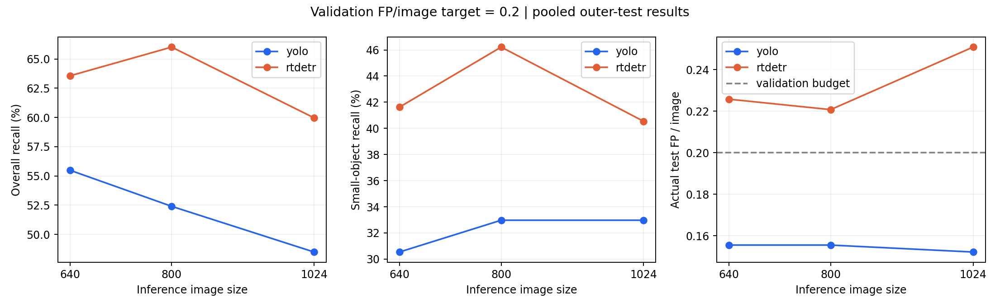

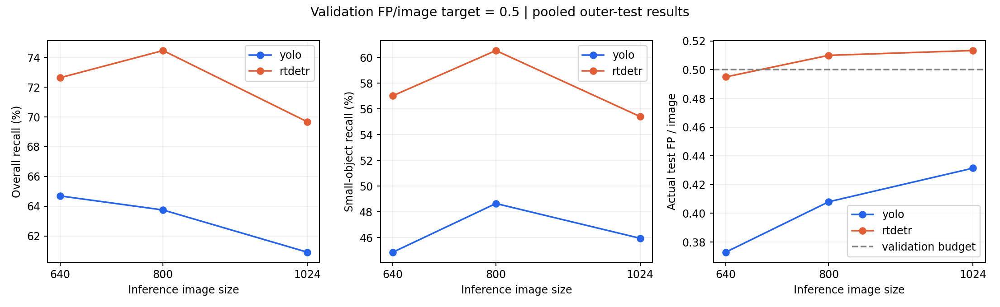

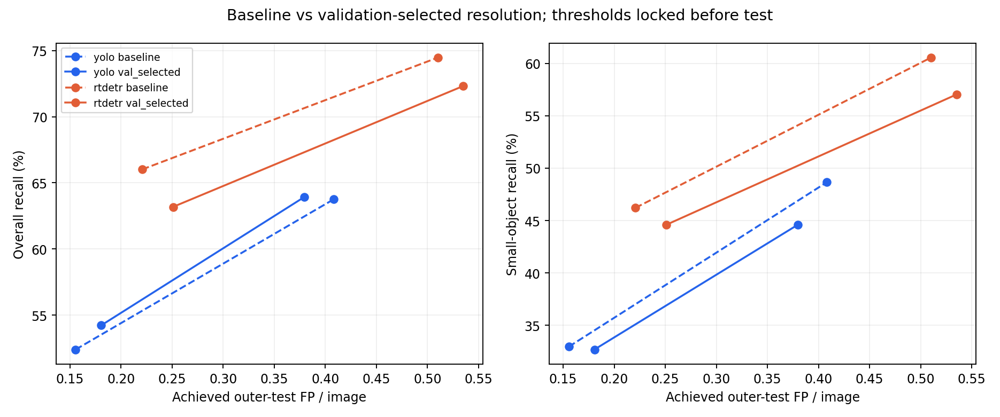

recovered_rtdetr_fold3_12ba02056929.png


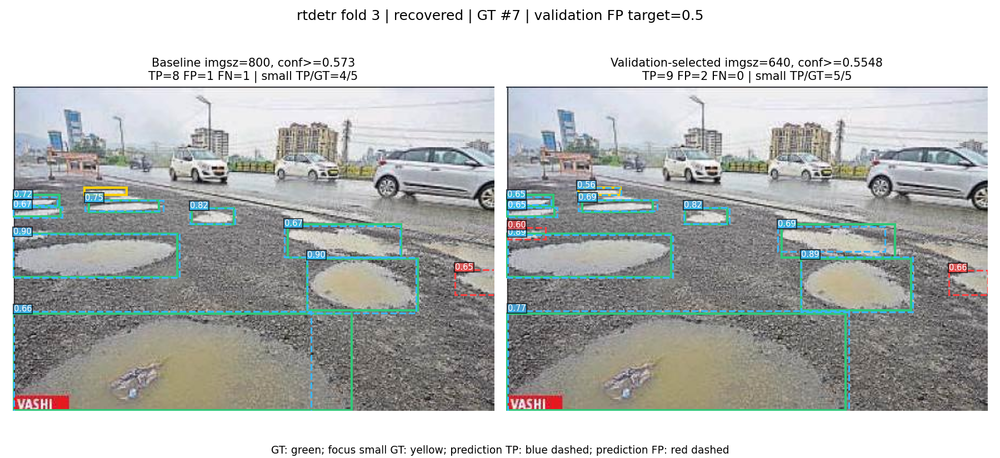

recovered_rtdetr_fold3_179a7e83830e.png


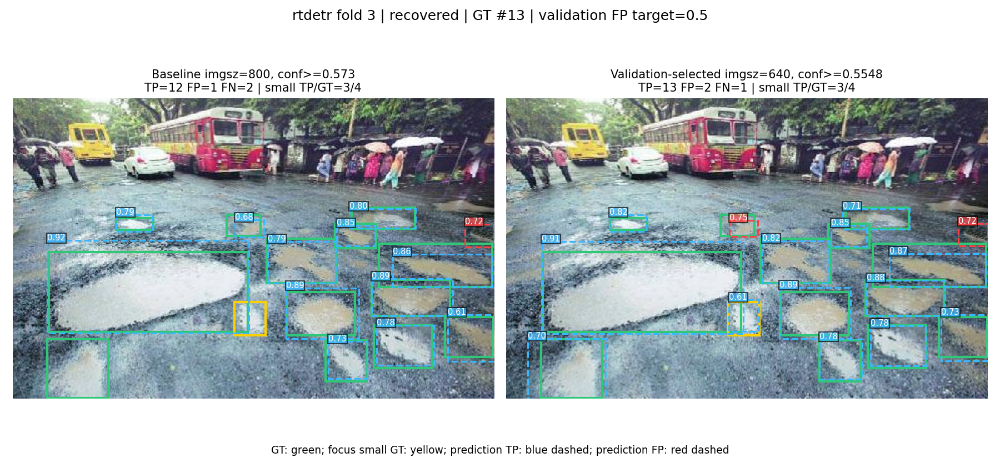

recovered_rtdetr_fold4_00e42da9dc28.png


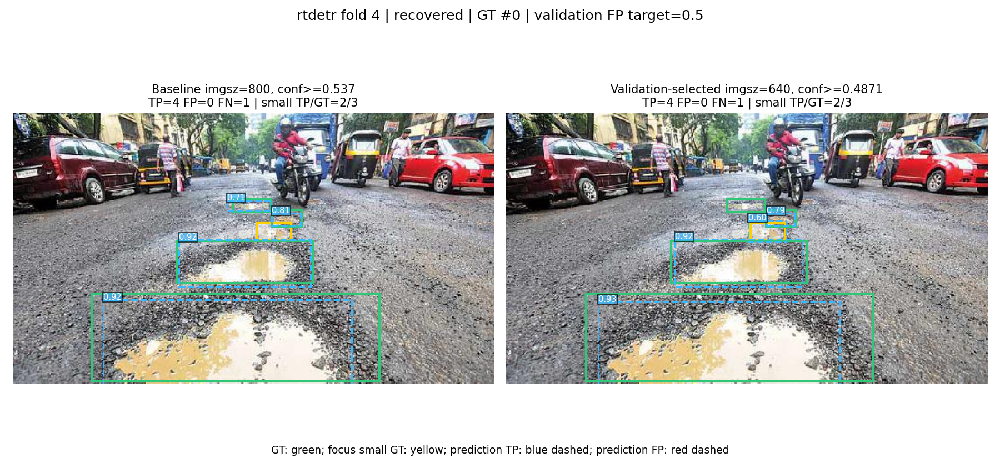

regressed_rtdetr_fold3_179a7e83830e.png


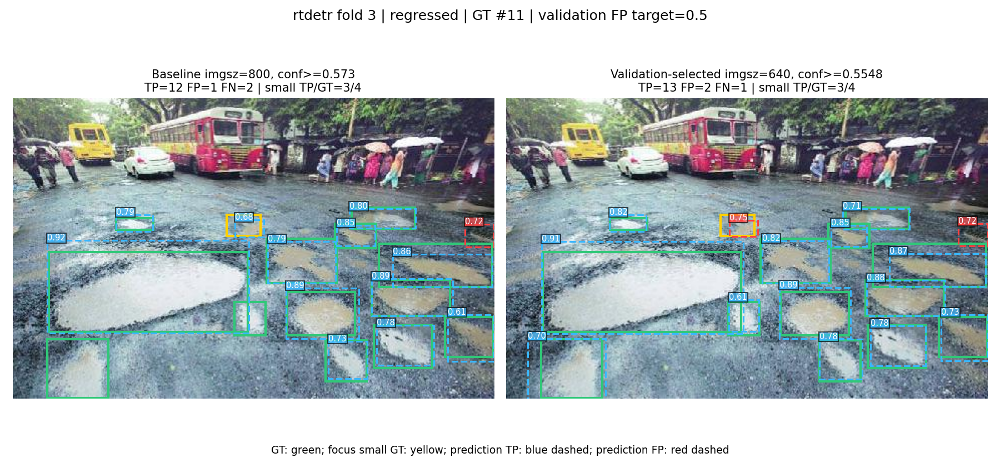

regressed_rtdetr_fold3_1d0eaed70434.png


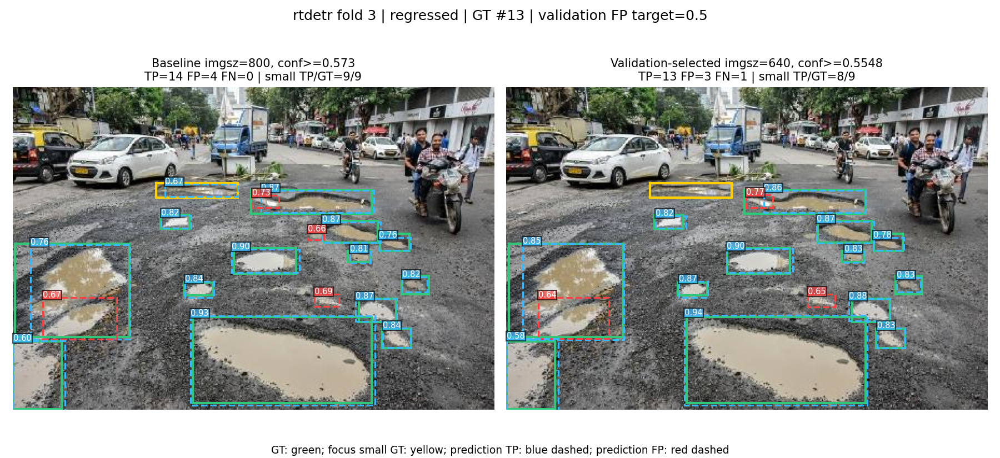

regressed_rtdetr_fold3_38325dbe3102.png


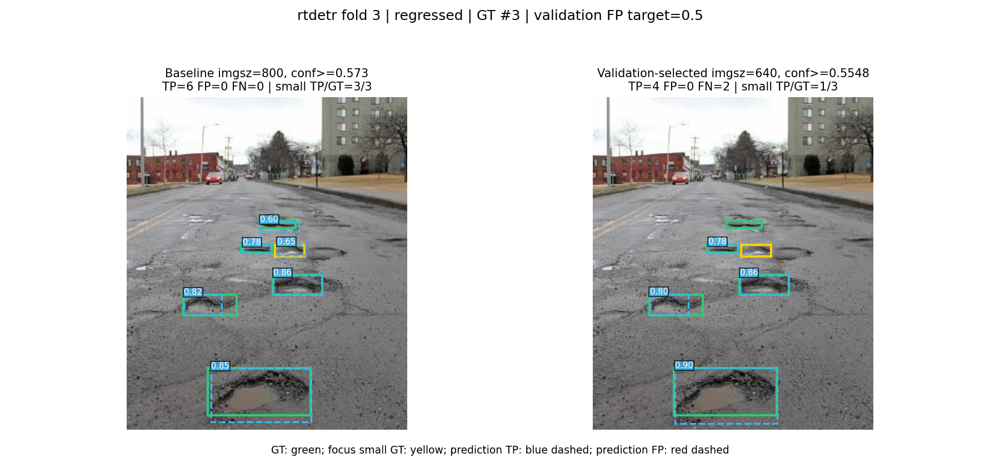

still_missed_rtdetr_fold1_02257e624737.png


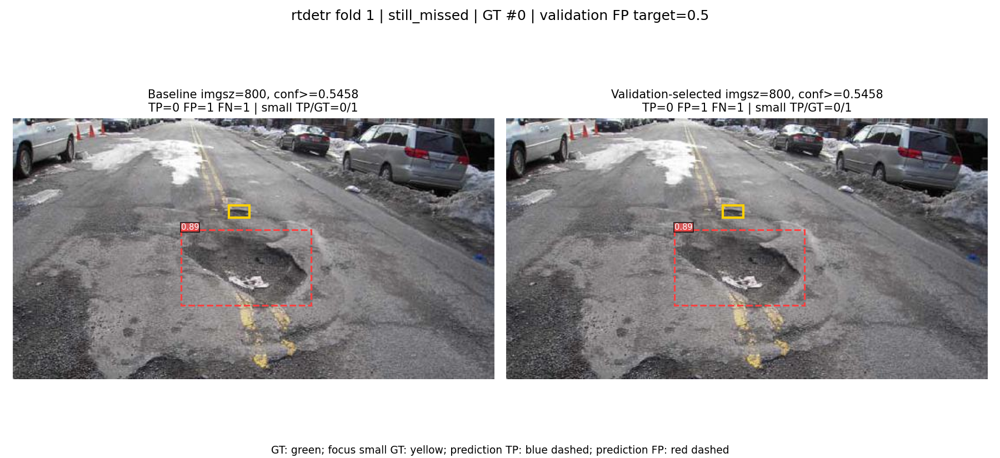

still_missed_rtdetr_fold1_0b0b42feab57.png


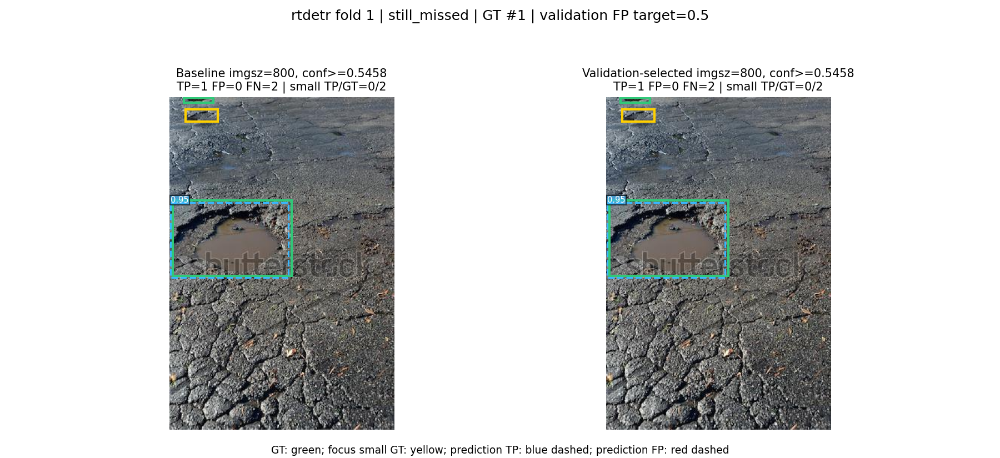

still_missed_rtdetr_fold1_152887308323.png


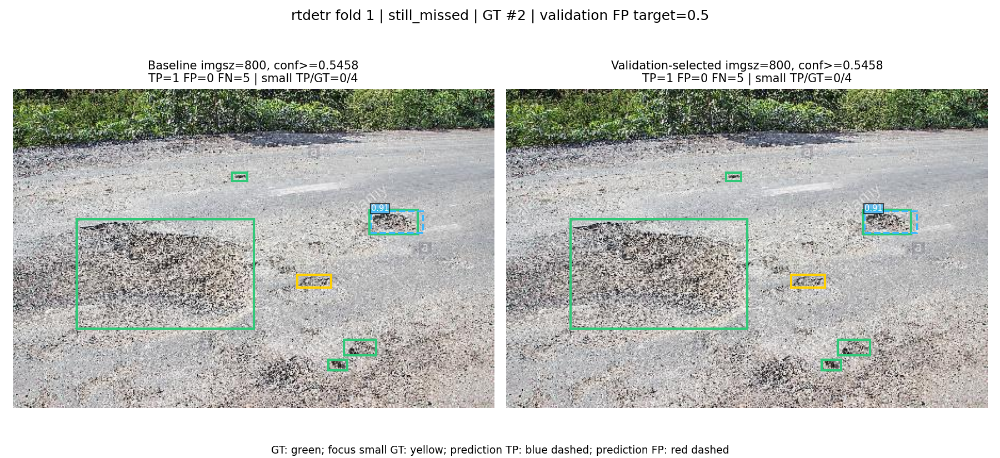

GT별 판정: /content/drive/MyDrive/Pothole/week7_fp_resolution_results/fp_resolution_20261031_113834_664819_UTC/gt_status.csv
미검출 유형 집계: /content/drive/MyDrive/Pothole/week7_fp_resolution_results/fp_resolution_20261031_113834_664819_UTC/miss_reason_counts.csv


In [16]:
from IPython.display import Image as DisplayImage
for target in CFG['targets']:
    display(DisplayImage(filename=str(OUT/f'resolution_target_{target:g}.png')))
display(DisplayImage(filename=str(OUT/'policy_operating_points.png')))

for path in sorted((OUT/'cases').glob('*.png')) if (OUT/'cases').exists() else []:
    print(path.name)
    display(DisplayImage(filename=str(path)))
print('GT별 판정:', OUT/'gt_status.csv')
print('미검출 유형 집계:', OUT/'miss_reason_counts.csv')


## 셀 9 · 결과 ZIP 다운로드 (선택)
결과는 Drive에 이미 저장됩니다. 이 셀은 현재 실행의 CSV·그림·설정·분석 코드를 ZIP으로 내려받습니다. 원본 이미지 전체와 모델 가중치는 복제하지 않으며, 별도 prediction_cache도 포함하지 않습니다.


In [17]:
import shutil
from google.colab import files
archive = shutil.make_archive('/content/week7_fp_resolution_results', 'zip', root_dir=str(OUT))
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 선택적 진단 · 다른 metadata 형식이 발견된 경우
이번 수정은 첨부 ZIP에서 확인한 source 목록 + fold index + 각 fold manifest 형식을 지원합니다. 다른 실행으로 교체해 형식 오류가 난 경우에만 아래 진단을 사용하세요. 저장된 분할을 임의로 재생성하지 않습니다.


In [ ]:
RUN_METADATA_DIAGNOSTIC = False
if RUN_METADATA_DIAGNOSTIC:
    for key in ('yolo_root', 'rtdetr_root'):
        if CFG[key] and Path(CFG[key]).is_dir():
            print(key, CFG[key])
            core.inspect_metadata(CFG[key], limit=10)


## 결과 파일과 해석

추가 파일: `recovery_audit.json`, `code/week7_split_recovery.py`. 복구 폴더에는 `splits.csv`, `verification.csv`, `labels/`가 저장됩니다. 원본/재생성 라벨의 저장 형식 차이를 기록하고, 예전 staged 라벨 해시와 동일한 파일을 평가에 사용합니다.


| 파일 | 내용 |
|---|---|
| `validation_grid.csv` | 모델·fold·해상도·FP 목표별 validation threshold와 성능 |
| `selected_resolution_inner_val.csv` | validation으로만 선택한 해상도와 선택 기준 |
| `decisions_locked.json` | test 평가 전에 고정한 결정 및 해시 |
| `outer_grid_by_fold.csv`, `grid_summary.csv` | 사전 지정한 전체 해상도의 test 결과 |
| `policy_by_fold.csv`, `policy_summary.csv` | baseline / validation 선택 정책의 성능 |
| `selected_vs_baseline.csv` | 같은 모델의 small Recall 차이·FN 감소·실제 FP 변화 |
| `rtdetr_vs_yolo.csv` | 두 모델 간 Recall 및 실제 FP 차이 |
| `gt_status.csv`, `image_results.csv` | GT별·이미지별 검출 상태 |
| `miss_reason_counts.csv` | GT 크기별 미검출 유형 집계 |
| `case_candidates.csv`, `case_images.csv`, `cases/` | 사례 후보·그림 목록·비교 이미지 |
| `protocol.json`, `verified_splits.csv`, `code/` | 설정·환경·파일 해시·분할·실행 코드 |
| `completed.json` | 모든 분석 단계 완료 표시 |

미검출 유형은 저장한 후보에서만 판단합니다: `below_threshold`(IoU≥0.5 후보가 threshold 미만), `matching_competition`(높은 score의 후보가 다른 GT와 매칭), `overlap_below_iou`(겹치는 후보가 있지만 IoU<0.5), `no_overlapping_cached_candidate`(겹치는 수집 후보 없음). 그림자·날씨·모델 구조 등의 인과관계를 증명하는 분류는 아닙니다.

- 원본 박스 면적 기준: small `<1024`, medium `[1024,9216)`, large `≥9216 px²`. COCO에서 널리 쓰는 32/96 경계를 참고하되 본 코드는 겹치지 않는 Recall 그룹을 명시적으로 사용합니다. **COCO APsmall과 직접 같은 지표로 비교하지 마세요.**
- batch=1, FP32, TTA 없음, rect=False. 모델별 기본 전처리·후처리 차이는 유지되며 RT-DETR에 추가 NMS를 넣지 않습니다.
- 전체 FP 예산을 사용합니다. 큰 객체나 배경에서 나온 FP도 제외하지 않습니다.
- `conf_floor=0.001` 이하 또는 `max_det=300` 밖의 후보는 관측되지 않습니다. 전체 수집 후보가 예산 안에 들어가면 더 낮은 score에서의 Recall이 제한될 수 있습니다.
- 본 노트북은 **추론 해상도 실험**입니다. 재학습, 새로운 증강, 타일링, COCO mAP, 실제 영상 FPS/latency 측정은 포함하지 않습니다.
- fold 표준편차를 독립 반복 실험의 유의성이나 신뢰구간으로 해석하지 않습니다.
- 합성 데이터 테스트 20개에서 매칭, size 경계, 없는 size의 N/A 처리, validation 선택, threshold 고정 후 test 실행, 누수 검사, 파일 출력과 사례 이미지를 검증했습니다. **첨부 metadata 전체와 실제 원본 이미지·라벨 1장을 추가로 검증했고, 복구부터 분석 결과 저장까지의 합성 테스트도 통과했습니다. 실제 598장 전체 및 GPU 모델 추론은 Colab 실행에서 확인해야 합니다.**

참고: [Ultralytics predict](https://docs.ultralytics.com/modes/predict/), [Threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html), [COCO evaluator 원본](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py). 공식 온라인 문서는 최신 버전일 수 있으므로 설치 버전은 실제 실행 기록과 일치시킵니다.


## 선택적 자체 테스트 · 합성 데이터만 사용
다음 셀은 테스트 파일을 `/content`에 저장합니다. 실행하려면 `RUN_SYNTHETIC_TESTS=True`로 바꾸세요. 실제 모델 성능을 측정하지 않으며 임시 합성 데이터를 사용합니다.


In [ ]:
RUN_SYNTHETIC_TESTS = False
if RUN_SYNTHETIC_TESTS:
    import subprocess
    from pathlib import Path
    test_sources = {'test_week7_fp_matched.py': '"""Synthetic correctness tests. These results are not research measurements."""\nimport contextlib\nimport io\nimport json\nimport tempfile\nimport unittest\nfrom pathlib import Path\nfrom unittest.mock import patch\n\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\n\nimport week7_fp_matched as w\n\n\ndef row(name, gt):\n    return {"image_id": name, "image": name, "gt": gt}\n\n\nclass EvaluationTests(unittest.TestCase):\n    def test_duplicates_and_negative_image_denominator(self):\n        rows = [row("positive", [[0, 0, 10, 10]]), row("background", [])]\n        pred = {"positive": {"boxes": [[0, 0, 10, 10]] * 2, "scores": [.9, .8]},\n                "background": {"boxes": [[5, 5, 8, 8]], "scores": [.7]}}\n        events = w.detection_events(rows, pred)\n        measured = w.evaluate_threshold(events, .7)\n        self.assertEqual((measured["tp"], measured["fp"], measured["fn"]), (1, 2, 0))\n        self.assertEqual(measured["fp_per_image"], 1)\n        selected = w.select_threshold(w.validation_curve(events), 0, .001)\n        self.assertEqual(selected["threshold"], .9)\n\n    def test_best_unmatched_ground_truth(self):\n        gt = [[0, 0, 10, 10], [2, 0, 12, 10]]\n        pred = {"a": {"boxes": [[0, 0, 10, 10], [1, 0, 11, 10]], "scores": [.9, .8]}}\n        m = w.evaluate_threshold(w.detection_events([row("a", gt)], pred), .5)\n        self.assertEqual(m["tp"], 2)\n\n    def test_tied_scores_cannot_be_partially_included(self):\n        events = (np.array([.8, .8]), np.array([1, 0]), 1, 1)\n        chosen = w.select_threshold(w.validation_curve(events), 0, .001)\n        self.assertGreater(chosen["threshold"], 1)\n        self.assertEqual(chosen["tp"], 0)\n        chosen = w.select_threshold(w.validation_curve(events), 1, .001)\n        self.assertEqual((chosen["tp"], chosen["fp"]), (1, 1))\n\n    def test_reject_confidence_one_and_empty_predictions(self):\n        events = (np.array([1.]), np.array([0]), 1, 1)\n        chosen = w.select_threshold(w.validation_curve(events), 0, .001)\n        self.assertEqual(w.evaluate_threshold(events, chosen["threshold"])["fp"], 0)\n        empty = (np.array([]), np.array([], dtype=int), 2, 3)\n        selected = w.select_threshold(w.validation_curve(empty), .5, .001)\n        self.assertEqual(selected["fn"], 2)\n        self.assertFalse(selected["precision_defined"])\n\n    def test_target_integer_budget_and_validation_only(self):\n        val = (np.array([.9, .8, .7]), np.array([1, 0, 1]), 2, 3)\n        chosen = w.select_threshold(w.validation_curve(val), .2, .001)  # floor(.6)=0\n        self.assertEqual(chosen["allowed_val_fp"], 0)\n        self.assertEqual(chosen["threshold"], .9)\n        test = (np.array([.95, .94]), np.array([0, 0]), 1, 1)\n        self.assertEqual(w.evaluate_threshold(test, chosen["threshold"])["fp"], 2)\n        self.assertEqual(chosen["threshold"], .9)  # no adjustment to test labels\n\n    def test_invalid_prediction_fails(self):\n        for boxes, scores in (([[0, 0, 0, 10]], [.8]), ([[0, 0, 1, 1]], [float(\'nan\')])):\n            with self.assertRaises(ValueError):\n                w.validate_prediction({"boxes": boxes, "scores": scores})\n\n    def test_exhaustive_threshold_selection(self):\n        rng = np.random.default_rng(43)\n        for _ in range(100):\n            scores = rng.choice([.1, .3, .5, .7, 1.], size=40)\n            labels = rng.integers(0, 2, size=40)\n            events = (scores, labels, 50, 7)\n            curve = w.validation_curve(events)\n            for target in [0, .2, .5, 1, 10]:\n                got = w.select_threshold(curve, target, .001)\n                candidates = []\n                for t in [w.REJECT_ALL, *set(scores)]:\n                    m = w.evaluate_threshold(events, t)\n                    if m[\'fp\'] <= int(np.floor(target * 7 + 1e-9)):\n                        candidates.append((m[\'tp\'], -m[\'fp\'], t))\n                self.assertEqual((got[\'tp\'], -got[\'fp\'], got[\'threshold\']), max(candidates))\n\n\ndef fixture(root):\n    images, labels = root / \'images\', root / \'labels\'\n    images.mkdir(); labels.mkdir()\n    for i in range(10):\n        Image.new(\'RGB\', (32, 32), (i * 20, 20, 40)).save(images / f\'{i}.png\')\n        (labels / f\'{i}.txt\').write_text(\'0 0.5 0.5 0.5 0.5\\n\')\n    records, folds = [], []\n    for k in range(1, 6):\n        test = {(k - 1) * 2, (k - 1) * 2 + 1}\n        val = {(k * 2) % 10, (k * 2 + 1) % 10}\n        d = {\'fold\': k}\n        for model in w.MODELS:\n            p = root / f\'{model}_fold{k}.pt\'\n            p.write_text(f\'FAKE TEST CHECKPOINT {model} {k}\')\n            d[model + \'_weights\'] = str(p)\n        folds.append(d)\n        for i in range(10):\n            split = \'outer_test\' if i in test else \'inner_val\' if i in val else \'train\'\n            records.append(dict(fold=k, split=split, image=str(images / f\'{i}.png\'),\n                                label=str(labels / f\'{i}.txt\'), group=f\'capture_{i}\'))\n    csv = root / \'splits.csv\'\n    pd.DataFrame(records).to_csv(csv, index=False)\n    cfg = {\'split_csv\': str(csv), \'folds\': 5, \'expected_images\': 10, \'expected_objects\': 10,\n           \'output_root\': str(root / \'outputs\'), \'targets\': [0, .5], \'conf_floor\': .001,\n           \'match_iou\': .5}\n    return folds, cfg\n\n\nclass IntegrationTests(unittest.TestCase):\n    def test_split_audit_and_synthetic_full_run(self):\n        with tempfile.TemporaryDirectory() as tmp, contextlib.redirect_stdout(io.StringIO()):\n            folds, cfg = fixture(Path(tmp))\n            prepared = w.prepare(folds, cfg)\n            self.assertEqual(prepared[\'audit\'][\'images\'], 10)\n            self.assertTrue(prepared[\'audit\'][\'groups_checked\'])\n            calls = []\n\n            def fake_predict(model, weights, weight_sha, rows, cfg, env):\n                split = rows[0][\'split\']\n                calls.append(split)\n                if split == \'outer_test\':\n                    locks = list(Path(cfg[\'output_root\']).glob(\'*/thresholds_locked.json\'))\n                    self.assertEqual(len(locks), 1)\n                    self.assertEqual(len(json.loads(locks[0].read_text())[\'thresholds\']), 20)\n                pred = {r[\'image_id\']: {\'boxes\': r[\'gt\'] + [[0, 0, 3, 3]],\n                                       \'scores\': [.9, .6 if model == \'yolo\' else .4]} for r in rows}\n                return pred, \'SYNTHETIC_CACHE_NOT_REAL\'\n\n            with patch.object(w, \'environment\', return_value={\'synthetic\': True}), \\\n                 patch.object(w, \'predict_split\', side_effect=fake_predict):\n                result = w.run(cfg, folds=folds, prepared=prepared)\n            self.assertEqual(calls[:10], [\'inner_val\'] * 10)\n            self.assertEqual(calls[10:], [\'outer_test\'] * 10)\n            self.assertEqual(len(result[\'results\']), 20)\n            self.assertEqual(len(result[\'summary\']), 4)\n            self.assertEqual(len(result[\'paired\']), 10)\n            self.assertTrue((result[\'out\'] / \'completed.json\').is_file())\n            self.assertEqual(len(list(result[\'out\'].glob(\'*.png\'))), 3)\n            for _, r in result[\'summary\'].iterrows():\n                self.assertEqual(r[\'pooled_images\'], 10)\n                self.assertEqual(r[\'pooled_recall\'], 1)\n\n    def test_image_leakage_rejected(self):\n        with tempfile.TemporaryDirectory() as tmp, contextlib.redirect_stdout(io.StringIO()):\n            folds, cfg = fixture(Path(tmp))\n            df = pd.read_csv(cfg[\'split_csv\'])\n            duplicate = df[(df.fold == 1) & (df.split == \'outer_test\')].iloc[0].copy()\n            duplicate[\'split\'] = \'inner_val\'\n            pd.concat([df, duplicate.to_frame().T]).to_csv(cfg[\'split_csv\'], index=False)\n            with self.assertRaisesRegex(ValueError, \'누수\'):\n                w.prepare(folds, cfg)\n\n    def test_group_leakage_rejected(self):\n        with tempfile.TemporaryDirectory() as tmp, contextlib.redirect_stdout(io.StringIO()):\n            folds, cfg = fixture(Path(tmp))\n            df = pd.read_csv(cfg[\'split_csv\'])\n            df[\'group\'] = \'same_video\'\n            df.to_csv(cfg[\'split_csv\'], index=False)\n            with self.assertRaisesRegex(ValueError, \'group 누수\'):\n                w.prepare(folds, cfg)\n\n    def test_original_holdout_repeated_across_folds_rejected(self):\n        with tempfile.TemporaryDirectory() as tmp, contextlib.redirect_stdout(io.StringIO()):\n            folds, cfg = fixture(Path(tmp))\n            df = pd.read_csv(cfg[\'split_csv\'])\n            first = df[df.fold == 1]\n            pd.concat([first.assign(fold=k) for k in range(1, 6)]).to_csv(cfg[\'split_csv\'], index=False)\n            with self.assertRaisesRegex(ValueError, \'정확히 한 번\'):\n                w.prepare(folds, cfg)\n\n    def test_yaml_lists_read_original_splits(self):\n        with tempfile.TemporaryDirectory() as tmp, contextlib.redirect_stdout(io.StringIO()):\n            root = Path(tmp)\n            folds, cfg = fixture(root)\n            df = pd.read_csv(cfg.pop(\'split_csv\'))\n            for fold in folds:\n                d = root / f"fold{fold[\'fold\']}"\n                d.mkdir()\n                for key, split in zip((\'train\', \'val\', \'test\'), w.SPLITS):\n                    names = df[(df.fold == fold[\'fold\']) & (df.split == split)].image\n                    (d / f\'{key}.txt\').write_text(\'\\n\'.join(names) + \'\\n\')\n                yaml_path = d / \'data.yaml\'\n                yaml_path.write_text(f\'path: {d}\\ntrain: train.txt\\nval: val.txt\\ntest: test.txt\\n\')\n                fold[\'data_yaml\'] = str(yaml_path)\n            prepared = w.prepare(folds, cfg)\n            self.assertEqual(prepared[\'audit\'][\'images\'], 10)\n\n\nif __name__ == \'__main__\':\n    unittest.main(verbosity=2)\n', 'test_fp_resolution.py': '"""Synthetic-only correctness tests; no real model accuracy is asserted."""\nimport contextlib\nimport io\nimport json\nimport os\nimport shutil\nimport tempfile\nimport unittest\nfrom pathlib import Path\nfrom unittest.mock import patch\n\nimport numpy as np\nimport pandas as pd\nimport week7_fp_matched as core\nimport week7_fp_resolution as exp\nfrom test_week7_fp_matched import fixture, row\n\n\nclass ResolutionTests(unittest.TestCase):\n    def test_original_area_disjoint_boundaries(self):\n        boxes = [[0,0,31,32], [0,0,32,32], [0,0,95,96], [0,0,96,96]]\n        area, labels = exp.area_bins(boxes)\n        self.assertEqual(labels.tolist(), [\'small\',\'medium\',\'medium\',\'large\'])\n        self.assertEqual(area.tolist(), [992,1024,9120,9216])\n\n    def test_size_recall_uses_matched_gt_and_global_fp(self):\n        rows = [row(\'a\', [[0,0,10,10],[20,20,70,70],[0,100,100,200]]), row(\'bg\', [])]\n        predictions = {\'a\':{\'boxes\':[[0,0,10,10],[0,0,10,10],[20,20,70,70]],\'scores\':[.9,.8,.7]},\n                       \'bg\':{\'boxes\':[[0,0,100,100]],\'scores\':[.9]}}\n        trace = exp.trace_split(rows,predictions)\n        m, detail, per_image = exp.score_trace(trace,.8,details=True)\n        self.assertEqual((m[\'tp\'],m[\'fp\'],m[\'fn\']),(1,2,2))\n        self.assertEqual(m[\'fp_per_image\'],1)\n        self.assertEqual(m[\'small_recall\'],1)\n        self.assertEqual(m[\'medium_recall\'],0)\n        self.assertEqual(m[\'large_recall\'],0)\n        self.assertEqual(detail[1][\'reason\'],\'below_threshold\')\n        self.assertEqual(len(per_image),2)\n\n    def test_no_small_gt_is_undefined_not_zero(self):\n        rows = [row(\'a\', [[0,0,100,100]])]\n        trace = exp.trace_split(rows, {\'a\':{\'boxes\':[], \'scores\':[]}})\n        m,_,_ = exp.score_trace(trace,.5)\n        self.assertEqual(m[\'small_gt\'],0)\n        self.assertIsNone(m[\'small_recall\'])\n        self.assertEqual(m[\'large_recall\'],0)\n\n    def test_matching_agrees_with_original_evaluator(self):\n        rng = np.random.default_rng(43)\n        for _ in range(20):\n            a = rng.uniform(0,80,(12,2))\n            boxes = np.c_[a,a+rng.uniform(2,30,(12,2))].tolist()\n            rows = [row(\'a\',boxes[:4])]\n            pred = {\'a\':{\'boxes\':boxes,\'scores\':rng.choice([.1,.3,.6,.9],12).tolist()}}\n            trace = exp.trace_split(rows,pred)\n            events = core.detection_events(rows,pred)\n            for t in [.1,.3,.6,.9,core.REJECT_ALL]:\n                got,_,_=exp.score_trace(trace,t)\n                for k,v in core.evaluate_threshold(events,t).items():\n                    self.assertEqual(got[k],v)\n\n    def test_resolution_selected_only_on_validation(self):\n        base = {\'fold\':1,\'model\':\'yolo\',\'target_fp_per_image\':.5,\'split\':\'inner_val\',\n                \'threshold\':.6,\'small_gt\':10,\'gt\':20,\'fp_per_image\':.2}\n        records = [{**base,\'imgsz\':640,\'small_recall\':.5,\'recall\':.8},\n                   {**base,\'imgsz\':800,\'small_recall\':.7,\'recall\':.75},\n                   {**base,\'imgsz\':1024,\'small_recall\':.7,\'recall\':.75}]\n        self.assertEqual(exp.choose_resolution(records)[0][\'selected_imgsz\'],800)\n        records[0][\'split\']=\'outer_test\'\n        with self.assertRaisesRegex(ValueError,\'inner_val\'):\n            exp.choose_resolution(records)\n\n    def test_no_small_validation_fallback(self):\n        records = [{\'fold\':1,\'model\':\'yolo\',\'target_fp_per_image\':.5,\'split\':\'inner_val\',\n                    \'threshold\':.8,\'small_gt\':0,\'gt\':20,\'fp_per_image\':.2,\'small_recall\':None,\n                    \'imgsz\':s,\'recall\':r} for s,r in [(640,.5),(800,.7),(1024,.6)]]\n        chosen=exp.choose_resolution(records)[0]\n        self.assertEqual(chosen[\'selected_imgsz\'],800)\n        self.assertEqual(chosen[\'selection_objective\'],\'overall_recall_no_small_gt\')\n        self.assertIsNone(chosen[\'val_small_recall\'])\n\n    def test_miss_reason_competition_and_location(self):\n        rows=[row(\'a\',[[0,0,10,10],[1,0,11,10],[20,20,30,30],[50,50,60,60]])]\n        pred={\'a\':{\'boxes\':[[0,0,10,10],[20,20,24,24]],\'scores\':[.9,.8]}}\n        _,detail,_=exp.score_trace(exp.trace_split(rows,pred),.5,details=True)\n        self.assertEqual([r[\'reason\'] for r in detail],\n                         [\'detected\',\'matching_competition\',\'overlap_below_iou\',\'no_overlapping_cached_candidate\'])\n\n    def test_full_grid_selection_lock_cases_and_output(self):\n        with tempfile.TemporaryDirectory() as tmp, contextlib.redirect_stdout(io.StringIO()):\n            root=Path(tmp)\n            folds,cfg=fixture(root)\n            cfg.update(resolutions=[640,800,1024],baseline_imgsz=800,case_target=.5,case_images_per_category=1)\n            prepared=core.prepare(folds,cfg)\n            calls=[]\n            def fake_predict(model,weights,sha,rows,local_cfg,env):\n                split=rows[0][\'split\']; size=local_cfg[\'imgsz\']; k=rows[0][\'fold\']\n                calls.append((split,size))\n                if split==\'outer_test\':\n                    locks=list(Path(local_cfg[\'output_root\']).glob(\'*/decisions_locked.json\'))\n                    self.assertEqual(len(locks),1)\n                    lock=json.loads(locks[0].read_text())\n                    self.assertEqual(len(lock[\'thresholds\']),60)\n                    self.assertEqual(len(lock[\'resolution_selection\']),20)\n                    self.assertTrue(all(d[\'selected_imgsz\']==1024 for d in lock[\'resolution_selection\']))\n                pred={}\n                for r in rows:\n                    i=int(Path(r[\'image\']).stem)\n                    found=(size==1024 or (size==800 and i%2==0))\n                    if split==\'outer_test\' and size==1024 and i in [0,3]:\n                        found=False\n                    boxes=r[\'gt\'][:] if found else []\n                    scores=[.9] if found else []\n                    boxes=boxes+[[0,0,3,3]]\n                    scores=scores+[.95 if split==\'outer_test\' and model==\'rtdetr\' else .2]\n                    pred[r[\'image_id\']]={\'boxes\':boxes,\'scores\':scores}\n                path=root/f\'fake_{k}_{model}_{size}_{split}.json\'\n                core.dump_json(path,{\'predictions\':pred})\n                return pred,str(path)\n            with patch.object(core,\'environment\',return_value={\'synthetic\':True}), \\\n                 patch.object(core,\'predict_split\',side_effect=fake_predict):\n                result=exp.run(cfg,folds,prepared)\n            self.assertEqual([s for s,_ in calls[:30]],[\'inner_val\']*30)\n            self.assertEqual([s for s,_ in calls[30:]],[\'outer_test\']*30)\n            self.assertEqual(len(result[\'grid\']),60)\n            self.assertEqual(len(result[\'decisions\']),20)\n            self.assertTrue(result[\'grid\'][\'test_budget_exceeded\'].any())\n            self.assertTrue((result[\'out\']/\'completed.json\').is_file())\n            self.assertEqual(set(result[\'cases\'][\'category\']),{\'recovered\',\'regressed\',\'still_missed\'})\n            self.assertEqual(len(list((result[\'out\']/\'cases\').glob(\'*.png\'))),3)\n            self.assertEqual(result[\'grid_summary\'][\'pooled_small_gt\'].unique().tolist(),[10])\n            if os.environ.get(\'TEST_PREVIEW_PATH\'):\n                shutil.copy2(next((result[\'out\']/\'cases\').glob(\'recovered*.png\')),os.environ[\'TEST_PREVIEW_PATH\'])\n\n\nif __name__==\'__main__\':\n    unittest.main(verbosity=2)\n', 'test_split_recovery.py': "import contextlib\nimport io\nimport json\nimport hashlib\nimport tempfile\nimport unittest\nfrom unittest.mock import patch\nfrom pathlib import Path\nfrom PIL import Image\nimport numpy as np\nimport pandas as pd\n\nimport week7_fp_matched as core\nimport week7_split_recovery as recovery\nimport week7_fp_resolution as experiment\nfrom test_week7_fp_matched import fixture\n\nREFERENCE = Path('/workspace/scratch/37db2ec8039f/work/split_recovery')\n\n\ndef recovery_fixture(root):\n    folds,cfg = fixture(root)\n    old = pd.read_csv(cfg['split_csv'])\n    sources, stage_labels = [], []\n    for i in range(10):\n        image = root/'images'/f'{i}.png'\n        label = root/'labels'/f'{i}.txt'\n        sources.append({'path':str(image),'relative_path':f'images/{i}.png',\n                        'width':32,'height':32,'pixel_sha256':recovery.legacy_pixel_sha256(core.decode_rgb(image)),\n                        'label_sha256':core.sha256_file(label),'group':f'g{i:06d}',\n                        'provided_group':None,'family':f'image_{i}'})\n        content = ('0 '+' '.join(f'{v:.12f}' for v in [.5,.5,.5,.5])+'\\n').encode()\n        stage_labels.append(hashlib.sha256(content).hexdigest())\n    split_docs = []\n    for f in folds:\n        k=f['fold'];rows=old[old.fold==k]; split={'fold':k}; stage=[]\n        for role,canonical in recovery.ROLE.items():\n            indices=[int(Path(p).stem) for p in rows[rows.split==canonical].image]\n            split[role]=indices\n            for i in indices:\n                stage.append({'split':role,'path':f'/content/deleted_staging/fold{k}/{role}/images/{i:06d}.png',\n                              'pixel_sha256':sources[i]['pixel_sha256'],'label_sha256':stage_labels[i],'objects':1})\n        split_docs.append(split)\n        run=root/f'fold{k}'/'run';run.mkdir(parents=True)\n        core.dump_json(run/'dataset_manifest.json',stage)\n        (run/'data.yaml').write_text(f'path: /content/deleted_staging/fold{k}\\ntrain: train/images\\nval: val/images\\ntest: test/images\\n')\n        f['data_yaml']=str(run/'data.yaml')\n    core.dump_json(root/'source_manifest.json',sources)\n    core.dump_json(root/'fold_indices.json',{'folds':split_docs,'method':'KFold'})\n    core.dump_json(root/'cv_config.json',{'data_root':str(root),'coordinate_eps':1e-6,'keep_local_staging':False})\n    cfg.update(yolo_root=str(root),data_root=str(root),split_csv=None)\n    return folds,cfg\n\n\nclass RecoveryTests(unittest.TestCase):\n    def test_uploaded_metadata_all_folds_match(self):\n        if not (REFERENCE/'metadata').exists():\n            self.skipTest('Attached research metadata is not part of the public test bundle.')\n        m=REFERENCE/'metadata'\n        cfg={'yolo_root':str(m/'run'),'expected_images':598,'expected_objects':1586}\n        folds=[{'fold':k,'data_yaml':str(m/f'fold{k}/data.yaml')} for k in range(1,6)]\n        result=recovery.load_metadata(cfg,folds)\n        self.assertEqual(len(result['assignments']),2990)\n        self.assertEqual(sum(r['objects'] for r in result['stage']),1586)\n        self.assertEqual([r['images'] for r in result['summary'] if r['split']=='outer_test'],[120,120,120,119,119])\n\n    def test_real_original_sample_reproduces_both_saved_hashes(self):\n        if not (REFERENCE/'reference_label.txt').exists():\n            self.skipTest('Original reference sample not bundled.')\n        source=json.loads((REFERENCE/'metadata/run/source_manifest.json').read_text())[0]\n        stage=next(r for r in json.loads((REFERENCE/'metadata/fold1/dataset_manifest.json').read_text())\n                   if r['pixel_sha256']==source['pixel_sha256'])\n        with tempfile.TemporaryDirectory() as tmp:\n            root=Path(tmp);image=root/source['relative_path'];image.parent.mkdir(parents=True)\n            image.write_bytes((REFERENCE/'reference_image.jpg').read_bytes())\n            label=core.label_for(image);label.parent.mkdir(parents=True)\n            label.write_bytes((REFERENCE/'reference_label.txt').read_bytes())\n            verified,content=recovery.verify_source(source,stage,root,1e-6)\n            self.assertEqual(verified['pixel_sha256'],source['pixel_sha256'])\n            self.assertEqual(hashlib.sha256(content).hexdigest(),stage['label_sha256'])\n            self.assertEqual(verified['objects'],1)\n\n    def test_full_recovery_into_prepare_and_idempotence(self):\n        with tempfile.TemporaryDirectory() as tmp,contextlib.redirect_stdout(io.StringIO()):\n            root=Path(tmp);folds,cfg=recovery_fixture(root)\n            first=recovery.recover(cfg,folds)\n            second=recovery.recover(cfg,folds)\n            self.assertEqual(first['csv'],second['csv'])\n            df=pd.read_csv(first['csv'],keep_default_na=False)\n            self.assertEqual(len(df),50)\n            self.assertEqual(set(df['group']),{''})\n            self.assertEqual(df.original_group.nunique(),10)\n            self.assertFalse(any('/deleted_staging/' in p for p in df.image))\n            self.assertEqual(len(list(first['out'].rglob('*.png'))),0)\n            cfg['split_csv']=str(first['csv'])\n            prepared=core.prepare(folds,cfg)\n            self.assertEqual(prepared['audit']['objects'],10)\n            self.assertFalse(prepared['audit']['groups_checked'])\n\n    def test_modified_source_pixels_rejected(self):\n        with tempfile.TemporaryDirectory() as tmp,contextlib.redirect_stdout(io.StringIO()):\n            root=Path(tmp);folds,cfg=recovery_fixture(root)\n            Image.new('RGB',(32,32),(123,24,90)).save(root/'images/0.png')\n            with self.assertRaisesRegex(ValueError,'pixel hash'):\n                recovery.recover(cfg,folds)\n\n    def test_modified_original_label_rejected(self):\n        with tempfile.TemporaryDirectory() as tmp,contextlib.redirect_stdout(io.StringIO()):\n            root=Path(tmp);folds,cfg=recovery_fixture(root)\n            (root/'labels/0.txt').write_text('0 0.4 0.4 0.3 0.3\\n')\n            with self.assertRaisesRegex(ValueError,'원본 라벨'):\n                recovery.recover(cfg,folds)\n\n    def test_membership_disagreement_rejected(self):\n        with tempfile.TemporaryDirectory() as tmp:\n            root=Path(tmp);folds,cfg=recovery_fixture(root)\n            p=root/'fold_indices.json';d=json.loads(p.read_text());f=d['folds'][0]\n            f['train'][0],f['val'][0]=f['val'][0],f['train'][0]\n            core.dump_json(p,d)\n            with self.assertRaisesRegex(ValueError,'split 불일치'):\n                recovery.load_metadata(cfg,folds)\n\n    def test_staging_label_hash_must_match(self):\n        with tempfile.TemporaryDirectory() as tmp,contextlib.redirect_stdout(io.StringIO()):\n            root=Path(tmp);folds,cfg=recovery_fixture(root)\n            # Consistent but wrong hash across all manifests must fail byte regeneration.\n            for f in folds:\n                p=Path(f['data_yaml']).parent/'dataset_manifest.json';rows=json.loads(p.read_text())\n                for r in rows:r['label_sha256']='0'*64\n                core.dump_json(p,rows)\n            with self.assertRaisesRegex(ValueError,'staged 라벨 해시'):\n                recovery.recover(cfg,folds)\n\n    def test_recovered_label_tampering_not_overwritten(self):\n        with tempfile.TemporaryDirectory() as tmp,contextlib.redirect_stdout(io.StringIO()):\n            root=Path(tmp);folds,cfg=recovery_fixture(root)\n            result=recovery.recover(cfg,folds)\n            p=result['out']/'labels/000000.txt';p.write_text('changed\\n')\n            with self.assertRaisesRegex(ValueError,'덮어쓰지'):\n                recovery.recover(cfg,folds)\n            self.assertEqual(p.read_text(),'changed\\n')\n\n    def test_recovery_to_full_comparison_pipeline(self):\n        with tempfile.TemporaryDirectory() as tmp,contextlib.redirect_stdout(io.StringIO()):\n            root=Path(tmp);folds,cfg=recovery_fixture(root)\n            cfg.update(resolutions=[640,800],baseline_imgsz=800,case_target=.5,case_images_per_category=0)\n            restored=recovery.recover(cfg,folds)\n            cfg['split_csv']=str(restored['csv'])\n            cfg['recovery_audit']=str(restored['out']/'recovery_audit.json')\n            prepared=core.prepare(folds,cfg)\n            prepared['sources'].extend(restored['sources'])\n            def predict(model,weights,sha,rows,local_cfg,env):\n                return {r['image_id']:{'boxes':r['gt'],'scores':[.9]*len(r['gt'])} for r in rows},'synthetic_cache'\n            with patch.object(core,'environment',return_value={'synthetic':True}), \\\n                 patch.object(core,'predict_split',side_effect=predict):\n                result=experiment.run(cfg,folds,prepared)\n            self.assertEqual(len(result['grid']),40)\n            self.assertTrue((result['out']/'recovery_audit.json').is_file())\n            self.assertTrue((result['out']/'code/week7_split_recovery.py').is_file())\n            self.assertTrue((result['out']/'completed.json').is_file())\n\n\nif __name__=='__main__':\n    unittest.main(verbosity=2)\n"}
    for name, source in test_sources.items():
        Path('/content', name).write_text(source, encoding='utf-8')
    subprocess.run([sys.executable, '-m', 'unittest', '-v',
                    'test_week7_fp_matched.py', 'test_fp_resolution.py', 'test_split_recovery.py'],
                   cwd='/content', check=True)
